# 01. Regression models: Linear, Ridge and Lasso

**Thesis:** Machine-Learning Prediction of Shear-Wave Velocity in the Dampier Sub-basin: Accuracy, Errors and Applications (D. Aldosaimani, Curtin University, 2026)

**What this notebook does:** Loads the eight wells, applies the quality control (measured Vs only; physical Vp limit), trains Linear, Ridge and Lasso regression with leave-one-well-out (LOWO) validation, selects the Lasso α, calculates SHAP input contributions, applies the models to the three wells without Vs, and runs the supporting data-quality checks used in the Discussion.

**Used in:** Sections 3.3–3.7 and 4.1–4.3

**Needs:** `DATA_DIR` and `LAS_DIR` (set in the Settings cell below)

**Writes:** LOWO results tables for Linear, Ridge and Lasso; `lasso_training_5wells.csv` (used by notebook 06)

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import lasio
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


## Settings

In [ ]:
# ---- Settings: set these paths before running ----
DATA_DIR    = Path("../data/processed")   # the eight *_with_formation.csv files (well logs with formation names)
LAS_DIR     = Path("../data/las")         # the eight *_LQC.las files from NOPIMS (project ENO0810814A)
RESULTS_DIR = Path("../results")          # results tables are written here
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load and combine all 8 wells


In [2]:
data_dir = DATA_DIR

well_logs = {}

for csv_file in sorted(data_dir.glob("*.csv")):
    well_name = csv_file.stem
    df = pd.read_csv(csv_file)
    df.insert(0, "Well Name", well_name)
    well_logs[well_name] = df
    print(f"{well_name}: {len(df)} samples")

data_df = pd.concat(well_logs.values(), ignore_index=True)
print(f"\nLoaded {len(well_logs)} wells, {len(data_df)} total samples")

wells = data_df['Well Name'].unique()

Angel_1_with_formation: 3657 samples
Angel_3_with_formation: 15205 samples
Egret_2_with_formation: 5287 samples
Lambert_8B_with_formation: 9385 samples
Nereus_1_with_formation: 9273 samples
Persephone_1_with_formation: 9706 samples
Seraph_1_with_formation: 1470 samples
Wanaea_11A_with_formation: 3087 samples

Loaded 8 wells, 57070 total samples


In [3]:
FIGURES_DIR = Path("figures_regression")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2b. Data cleaning (final)

Two cleaning steps, in this order:

1. **Remove impossible Vp.** At each depth, Vp is compared with the fastest Vp its minerals could have at zero porosity (stiffest possible mix of quartz, calcite and illite; illite given quartz properties, so the limit is deliberately high). Any reading above it cannot be real rock.
2. **Keep only real, unchanged measured Vs** in the 5 measured wells. `VS_EDITED_V2` (the target) is compared with `VS_ORG` (the recorded shear log in the LAS file):

| Type | Meaning | Kept? |
|---|---|---|
| Real, unchanged | `VS_ORG` exists and `VS_EDITED_V2` is within 2% of it | **Yes** |
| Real, edited by SLB | `VS_ORG` exists but `VS_EDITED_V2` differs by more than 2% (SLB replaced poor-quality measured Vs with modelled values, Barlass et al., 2024, §18.1.4.2) | No |
| Modelled | No `VS_ORG`: Vs was calculated from Vp by SLB | No |

Not applied, on purpose:
- **Washouts are kept.** Section 2c finds them; the check after the final Lasso model (Section 8) compares the error in washed-out and in-gauge depths of the same formation. The effect is formation-dependent (no increase in two formations, a moderate increase in the Withnell Fm and Muderong Shale), and removing washouts would discard about a fifth of Egret_2, so they are kept and the effect is reported as a limitation.
- **No rule based on Vs itself** (e.g. Vp/Vs > 2.5): removing depths because their Vs looks unusual would remove the hard cases and make the scores look better than they are.

The 3 modelled-only wells (Angel_1, Angel_3, Wanaea_11A) only go through step 1; they are never used for training or LOWO testing, only predicted in Part 2.


In [4]:
# --- Remove physically impossible Vp (faster than the rock's own minerals) ---
# Upper limit at each depth = stiffest possible (Voigt) mix of its minerals at zero porosity.
# Clay (illite) is given the stiffness of quartz. Real clay is softer, so this limit is
# deliberately too high: it can only remove readings that no real rock could produce.
# Mineral properties from Mavko et al. (2009): K and mu in GPa, rho in g/cc
QUARTZ  = dict(K=37.0, mu=44.0, rho=2.65)     # solid quartz:  Vp ~ 6010 m/s
CALCITE = dict(K=76.8, mu=32.0, rho=2.71)     # solid calcite: Vp ~ 6640 m/s
REMOVE_IMPOSSIBLE_VP = True

def p_modulus(mineral):                        # P-wave modulus M = K + 4/3 mu
    return mineral['K'] + 4 / 3 * mineral['mu']

solid = data_df[['QUARTZ_COMBINER', 'CALCITE_COMBINER', 'ILLITE_COMBINER']].sum(axis=1)
f_calcite = data_df['CALCITE_COMBINER'] / solid      # calcite fraction of the solid rock
f_other = 1 - f_calcite                               # quartz + illite (both given quartz properties)

M   = f_other * p_modulus(QUARTZ) + f_calcite * p_modulus(CALCITE)      # GPa
rho = f_other * QUARTZ['rho'] + f_calcite * CALCITE['rho']               # g/cc
data_df['VP_LIMIT'] = np.sqrt(M / rho) * 1000                             # km/s -> m/s
data_df['vp_impossible'] = data_df['VP_EDITED'] > data_df['VP_LIMIT']

bad = data_df[data_df['vp_impossible']]
print(f"Depths with Vp faster than their minerals allow: {len(bad)}")
display(bad[['Well Name', 'MD', 'Formation', 'VP_EDITED', 'VP_LIMIT']].round(1))

if REMOVE_IMPOSSIBLE_VP:
    data_df = data_df[~data_df['vp_impossible']].reset_index(drop=True)
    print(f"Removed. Rows left: {len(data_df)}")


Depths with Vp faster than their minerals allow: 6


,Well Name,MD,Formation,VP_EDITED,VP_LIMIT
19480,Egret_2_with_formation,2720.5,Withnell Fm,7819.4,6289.8
19644,Egret_2_with_formation,2745.5,Withnell Fm,7181.5,6609.1
19645,Egret_2_with_formation,2745.6,Withnell Fm,7411.0,6609.6
19646,Egret_2_with_formation,2745.8,Withnell Fm,7115.9,6609.4
19749,Egret_2_with_formation,2761.5,Withnell Fm,6502.3,6437.3
53598,Seraph_1_with_formation,2977.1,Angel Fm,6146.5,6008.4


Removed. Rows left: 57064


In [5]:
# --- Keep only real measured Vs (compare VS_EDITED_V2 with VS_ORG from the LAS files) ---
from pathlib import Path


MEASURED_ONLY = True   # remove depths where Vs is not a real measurement
DROP_EDITED   = True   # also remove depths where SLB changed the measured Vs by more than EDIT_TOL
EDIT_TOL      = 0.02   # 2%, same threshold as the checks in Part 3

measured_names = ['Egret_2', 'Lambert_8B', 'Nereus_1', 'Persephone_1', 'Seraph_1']
data_df['VS_ORG'] = np.nan             # modelled-only wells stay empty

for w in measured_names:
    d = lasio.read(list(LAS_DIR.rglob(f"{w}_LQC.las"))[0]).df().reset_index()
    d.columns = d.columns.str.upper()
    d = d.rename(columns={d.columns[0]: 'MD'})
    d = d[['MD', 'VS_ORG']].sort_values('MD')

    idx = data_df['Well Name'].str.contains(w)
    sub = data_df.loc[idx, ['MD']].reset_index().sort_values('MD')
    merged = pd.merge_asof(sub, d, on='MD', direction='nearest', tolerance=0.1)
    data_df.loc[merged['index'], 'VS_ORG'] = merged['VS_ORG'].values

has_org = data_df['VS_ORG'].notna()
edited = has_org & ((data_df['VS_EDITED_V2'] - data_df['VS_ORG']).abs() / data_df['VS_ORG'] > EDIT_TOL)
data_df['VS_MEASURED'] = (has_org & ~edited) if DROP_EDITED else has_org

# Summary per measured well
in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
names = data_df.loc[in_measured_well, 'Well Name']
summary = pd.DataFrame({
    'rows': names.value_counts().sort_index(),
    '% real, unchanged': (100 * (has_org & ~edited)[in_measured_well].groupby(names).mean()).round(1),
    '% real, edited by SLB': (100 * edited[in_measured_well].groupby(names).mean()).round(1),
    '% modelled (no VS_ORG)': (100 * (~has_org)[in_measured_well].groupby(names).mean()).round(1),
})
print(summary)

if MEASURED_ONLY:
    data_df = data_df[~in_measured_well | data_df['VS_MEASURED']].reset_index(drop=True)
    print("\nRows kept per well:")
    print(data_df.groupby('Well Name').size())

    # Check: every row left in the 5 measured wells is a real measurement
    in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
    assert data_df.loc[in_measured_well, 'VS_MEASURED'].all()
    print("\nCheck passed: all rows left in the 5 measured wells are real measured Vs")


                             rows  % real, unchanged  % real, edited by SLB  \
Well Name                                                                     
Egret_2_with_formation       5282               85.3                   14.1   
Lambert_8B_with_formation    9385              100.0                    0.0   
Nereus_1_with_formation      9273               96.5                    2.9   
Persephone_1_with_formation  9706               32.2                    1.0   
Seraph_1_with_formation      1469               53.3                    2.2   

                             % modelled (no VS_ORG)  
Well Name                                            
Egret_2_with_formation                          0.6  
Lambert_8B_with_formation                       0.0  
Nereus_1_with_formation                         0.6  
Persephone_1_with_formation                    66.8  
Seraph_1_with_formation                        44.5  

Rows kept per well:
Well Name
Angel_1_with_formation          3657


## 2c. Data-quality checks (diagnostic only: nothing is removed here)

- **Vp check:** Vp per well, and any interval still faster than solid quartz (6000 m/s) after cleaning, with its minerals.
- **Caliper check:** hole size compared with the bit size, per well and per formation. Washouts are flagged here and tested against the Lasso errors after Section 8's final model.

In [6]:
# --- Vp check: where is Vp high? (5 measured wells, after cleaning) ---
# Speed of the solid minerals (zero porosity). A rock made of them cannot be faster.
VP_QUARTZ, VP_CALCITE = 6000, 6600     # m/s, approx. solid quartz and solid calcite

m = data_df[data_df['Well Name'].str.contains('|'.join(measured_names))].copy()
m['Well'] = m['Well Name'].str.replace('_with_formation', '')

# Mineral fractions of the solid part only (the COMBINER curves are fractions of the whole rock, pores included)
minerals = ['QUARTZ_COMBINER', 'CALCITE_COMBINER', 'ILLITE_COMBINER']
solid = m[minerals].sum(axis=1)
for col in minerals:
    m[col.split('_')[0].lower()] = m[col] / solid           # -> 'quartz', 'calcite', 'illite'

# Caliper: how much bigger than the well's normal hole size (its median), in inches
m['cali_excess'] = m['CALI_EDITED'] - m.groupby('Well')['CALI_EDITED'].transform('median')

# Table 1: one row per well
per_well = m.groupby('Well').agg(
    rows=('MD', 'size'),
    vp_median=('VP_EDITED', 'median'),
    vp_max=('VP_EDITED', 'max'),
    n_above_6000=('VP_EDITED', lambda v: (v > VP_QUARTZ).sum()),
    n_above_6600=('VP_EDITED', lambda v: (v > VP_CALCITE).sum()),
).round(0)
print("Table 1 - Vp per well")
display(per_well)

# Table 2: every depth interval where Vp is faster than solid quartz
hi = m[m['VP_EDITED'] > VP_QUARTZ].sort_values(['Well', 'MD']).copy()
hi['interval'] = ((hi['Well'] != hi['Well'].shift()) | (hi['MD'].diff() > 1.5)).cumsum()
intervals = hi.groupby('interval').agg(
    Well=('Well', 'first'),
    Formation=('Formation', 'first'),
    top=('MD', 'min'),
    base=('MD', 'max'),
    rows=('MD', 'size'),
    vp_max=('VP_EDITED', 'max'),
    calcite=('calcite', 'median'),
    quartz=('quartz', 'median'),
    illite=('illite', 'median'),
    cali_excess_max=('cali_excess', 'max'),
).round(2).reset_index(drop=True)
print(f"\nTable 2 - intervals with Vp > {VP_QUARTZ} m/s (faster than solid quartz)")
display(intervals)


Table 1 - Vp per well


,rows,vp_median,vp_max,n_above_6000,n_above_6600
Well,,,,,
Egret_2,4506,3916.0,5912.0,0,0
Lambert_8B,9385,3390.0,5011.0,0,0
Nereus_1,8947,3546.0,5070.0,0,0
Persephone_1,3128,3738.0,5417.0,0,0
Seraph_1,783,3782.0,5958.0,0,0



Table 2 - intervals with Vp > 6000 m/s (faster than solid quartz)


,Well,Formation,top,base,rows,vp_max,calcite,quartz,illite,cali_excess_max


In [7]:
# --- Caliper check, 5 measured wells (uses the table m from the Vp check above) ---
# Bit size (drilled hole size). Not stored in the LAS files, so read off the caliper where the
# hole is in gauge: Seraph_1 changes from 12.25 in to 8.5 in hole at about 2960 m.
BIT_SIZE = {                      # well: [(from MD, to MD, bit size in inches)]
    'Egret_2':      [(0, 9999, 12.25)],
    'Lambert_8B':   [(0, 9999, 12.25)],
    'Nereus_1':     [(0, 9999, 8.5)],
    'Persephone_1': [(0, 9999, 12.25)],
    'Seraph_1':     [(0, 2960, 12.25), (2960, 9999, 8.5)],
}
WASHOUT_IN = 2.0                  # hole more than 2 in bigger than the bit = washout

m['bit'] = np.nan
for well, sections in BIT_SIZE.items():
    for top, base, bit in sections:
        m.loc[(m['Well'] == well) & (m['MD'] >= top) & (m['MD'] < base), 'bit'] = bit

m['excess'] = m['CALI_EDITED'] - m['bit']                 # inches over bit size
m['cali_bad'] = m['excess'] < -1.0                        # caliper reading far below bit size = tool not working
m['washout'] = ~m['cali_bad'] & (m['excess'] > WASHOUT_IN)

# Table 3: one row per well
cal_well = m.groupby('Well').agg(
    rows=('MD', 'size'),
    excess_median=('excess', 'median'),
    pct_over_1in=('excess', lambda e: 100 * (e > 1).mean()),
    pct_washout=('washout', lambda w: 100 * w.mean()),
    excess_max=('excess', 'max'),
    caliper_not_working=('cali_bad', 'sum'),
).round(2)
print(f"Table 3 - caliper per well (excess = caliper minus bit size, inches; washout = more than {WASHOUT_IN} in)")
display(cal_well)

# Table 4: formations that contain washouts
cal_fm = m.groupby(['Well', 'Formation'], sort=False).agg(
    top=('MD', 'min'),
    base=('MD', 'max'),
    rows=('MD', 'size'),
    excess_median=('excess', 'median'),
    washout_rows=('washout', 'sum'),
    pct_washout=('washout', lambda w: 100 * w.mean()),
    excess_max=('excess', 'max'),
).round(2)
cal_fm = cal_fm[cal_fm['washout_rows'] > 0].reset_index()
print("\nTable 4 - formations with washouts")
display(cal_fm)


Table 3 - caliper per well (excess = caliper minus bit size, inches; washout = more than 2.0 in)


,rows,excess_median,pct_over_1in,pct_washout,excess_max,caliper_not_working
Well,,,,,,
Egret_2,4506,1.28,66.13,19.15,4.15,149
Lambert_8B,9385,-0.02,0.45,0.42,6.43,2
Nereus_1,8947,-0.02,0.00,0.00,0.26,0
Persephone_1,3128,0.16,0.51,0.06,2.33,0
Seraph_1,783,0.05,19.54,11.62,8.35,0



Table 4 - formations with washouts


,Well,Formation,top,base,rows,excess_median,washout_rows,pct_washout,excess_max
0,Egret_2,Miria Marl,2626.31,2644.44,120,3.50,120,100.00,4.15
1,Egret_2,Withnell Fm,2644.60,2817.42,1103,2.02,564,51.13,4.09
2,Egret_2,Toolonga Calcilutite,2817.57,2874.87,230,2.22,161,70.00,4.10
3,Egret_2,Angel Fm,3209.70,3431.90,1435,0.22,18,1.25,2.39
4,Lambert_8B,Delambre/Mandu Fms,1700.16,2012.88,2053,-0.02,39,1.90,6.43
5,Persephone_1,Calypso Fm,3096.06,3117.85,144,0.45,2,1.39,2.33
6,Seraph_1,Toolonga /Haycock Fms,2200.08,2326.08,123,0.04,2,1.63,2.57
7,Seraph_1,Muderong Shale,2394.08,2568.08,147,1.95,72,48.98,5.98
8,Seraph_1,Angel Fm,2732.08,2978.08,225,-0.03,11,4.89,5.69
9,Seraph_1,Dingo Clst,2994.08,3187.08,114,0.02,6,5.26,8.35


## 3. Define well groups (measured vs modelled-only)



In [8]:
measured_wells = [
    'Egret_2_with_formation',
    'Lambert_8B_with_formation',
    'Nereus_1_with_formation',
    'Persephone_1_with_formation',
    'Seraph_1_with_formation',
]

modelled_wells = [
    'Angel_1_with_formation',
    'Angel_3_with_formation',
    'Wanaea_11A_with_formation',
]

print("Measured wells (used for LOWO validation):", len(measured_wells))
print("Modelled-only wells (used later in Part 2 only):", len(modelled_wells))

Measured wells (used for LOWO validation): 5
Modelled-only wells (used later in Part 2 only): 3


## 4. Define features and target

5 features. Two changes from the earlier 6-feature set, per Olivia's feedback:

- Resistivity is fed in as `RESD_LOG` (log10 of RESD_EDITED), not the raw ohm-m values. Resistivity is a log-normally distributed quantity, so a log10 transform is standard practice before feeding it into a linear model — the earlier version used raw RESD_EDITED directly, which is now corrected.
- `VCL_GEO_QEPP` (clay volume) has been dropped — it's derived from GR_EDITED, so keeping both as separate model inputs double-counts the same information.

In [9]:
data_df['RESD_LOG'] = np.log10(data_df['RESD_EDITED'])

features_reg = [
    'GR_EDITED',
    'RHOB_EDITED',
    'NPHI_EDITED',
    'RESD_LOG',
    'VP_EDITED',
]

target_reg = 'VS_EDITED_V2'

missing = data_df[features_reg + [target_reg]].isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values in features/target")

No missing values in features/target


## 5. Correlation matrix

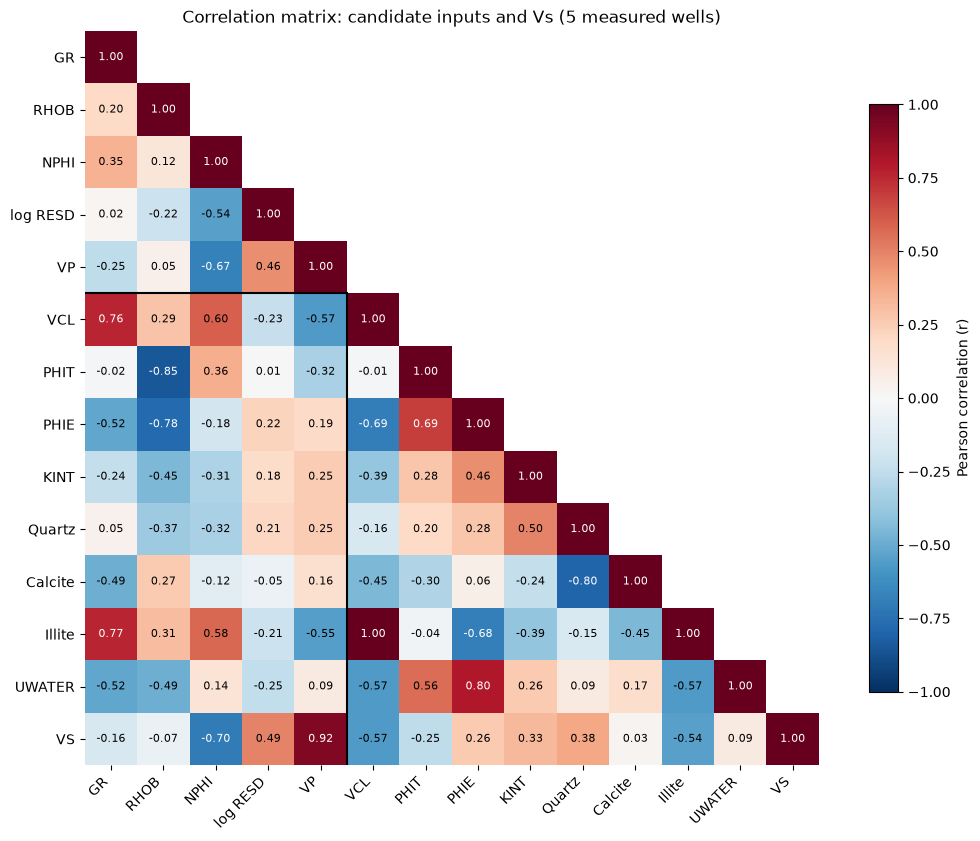

In [10]:
# --- Candidate inputs + target ---
cand = ['GR_EDITED', 'RHOB_EDITED', 'NPHI_EDITED', 'RESD_LOG', 'VP_EDITED',
        'VCL_GEO_QEPP', 'PHIT_QEPP', 'PIGN_QEPP', 'KINT_GEO_QEPP',
        'QUARTZ_COMBINER', 'CALCITE_COMBINER', 'ILLITE_COMBINER', 'UWATER_COMBINER']
corr_cols = cand + [target_reg]

labels = ['GR', 'RHOB', 'NPHI', 'log RESD', 'VP',
          'VCL', 'PHIT', 'PHIE', 'KINT',
          'Quartz', 'Calcite', 'Illite', 'UWATER', 'VS']

# --- Correlation on the 5 measured wells only ---
corr_matrix = data_df[data_df['Well Name'].isin(measured_wells)][corr_cols].corr()

# --- Show lower triangle only (each value once) ---
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
corr_plot = corr_matrix.mask(mask)

n = len(corr_cols)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_plot, cmap='RdBu_r', vmin=-1, vmax=1)

# --- Axis labels ---
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(labels, fontsize=10)

# --- Write values (skip hidden upper half) ---
for i in range(n):
    for j in range(n):
        val = corr_plot.iloc[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', fontsize=8,
                    color='white' if abs(val) > 0.6 else 'black')

# --- Lines separating the 5 selected inputs (inside lower triangle only) ---
ax.plot([-0.5, 4.5], [4.5, 4.5], color='black', lw=1.5)
ax.plot([4.5, 4.5], [4.5, n - 0.5], color='black', lw=1.5)
ax.set_xlim(-0.5, n - 0.5)
ax.set_ylim(n - 0.5, -0.5)

# --- Clean up frame ---
for spine in ax.spines.values():
    spine.set_visible(False)

fig.colorbar(im, ax=ax, label='Pearson correlation (r)', shrink=0.8)
ax.set_title('Correlation matrix: candidate inputs and Vs (5 measured wells)', fontsize=12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
plt.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

## 5b. Feature & target distributions

Histograms of each input feature and the target, across the 5 measured wells -- checks the range and shape of the data actually going into the models, and flags any well that looks unusual before it shows up as a LOWO accuracy problem.

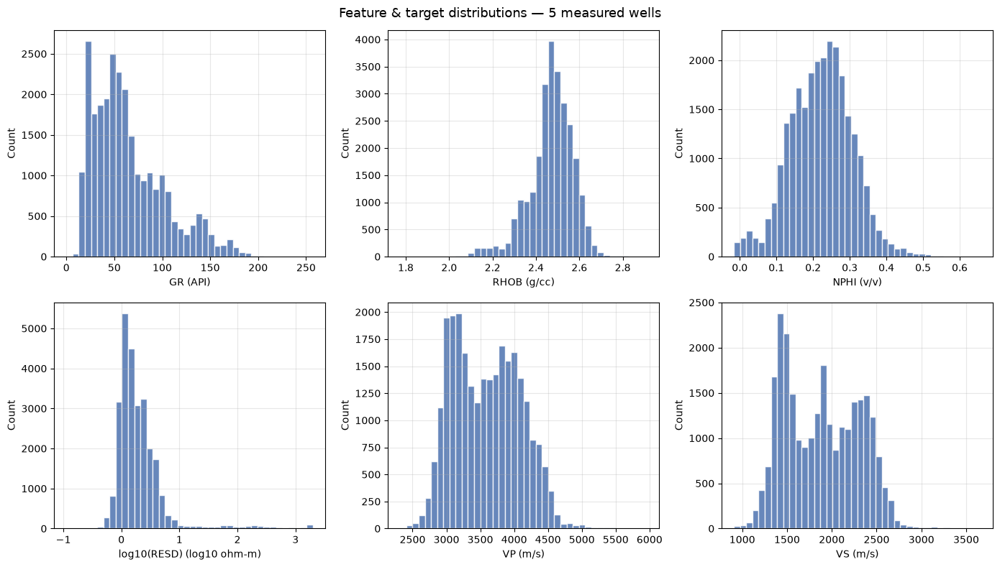

In [11]:
plot_cols = features_reg + [target_reg]
plot_labels = {
    'GR_EDITED': 'GR (API)',
    'RHOB_EDITED': 'RHOB (g/cc)',
    'NPHI_EDITED': 'NPHI (v/v)',
    'RESD_LOG': 'log10(RESD) (log10 ohm-m)',
    'VP_EDITED': 'VP (m/s)',
    'VS_EDITED_V2': 'VS (m/s)',
}

measured_for_hist = data_df[data_df['Well Name'].isin(measured_wells)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    ax.hist(measured_for_hist[col].dropna(), bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)
    ax.set_xlabel(plot_labels.get(col, col))
    ax.set_ylabel('Count')
    ax.grid(alpha=0.3)

fig.suptitle('Feature & target distributions — 5 measured wells', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_target_distributions.png", dpi=300, bbox_inches='tight')
plt.show()


## 6. Linear Regression — LOWO cross-validation (5 measured wells)

Each fold holds out one of the 5 measured wells and trains on the other 4 — the 3 modelled-only wells are excluded from training entirely, not just from thme reported average. This means every number in this section, both training and testing, comes from real measured Vs.

In [12]:
results = []

for val_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    model = LinearRegression()
    model.fit(train_df[features_reg], train_df[target_reg])

    pred = model.predict(val_df[features_reg])

    r2 = r2_score(val_df[target_reg], pred)
    rmse = np.sqrt(mean_squared_error(val_df[target_reg], pred))
    mae = mean_absolute_error(val_df[target_reg], pred)

    results.append({
        'Validation Well': val_well,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae
    })

results_lr = pd.DataFrame(results)
results_lr['Model'] = 'Linear Regression'
results_lr = results_lr[['Model', 'Validation Well', 'R2', 'RMSE', 'MAE']]
results_lr.to_csv(RESULTS_DIR / 'lowo_linear_regression.csv', index=False)

print("Mean R2:", results_lr['R2'].mean())
print("Mean RMSE:", results_lr['RMSE'].mean())
print("Mean MAE:", results_lr['MAE'].mean())

results_lr

Mean R2: 0.6825130006808756
Mean RMSE: 176.21052452937414
Mean MAE: 139.42807137661268


,Model,Validation Well,R2,RMSE,MAE
0,Linear Regression,Egret_2_with_formation,0.772909,181.366045,122.370716
1,Linear Regression,Lambert_8B_with_formation,0.901321,93.661428,69.831069
2,Linear Regression,Nereus_1_with_formation,0.878409,154.923149,128.895534
3,Linear Regression,Persephone_1_with_formation,-0.086012,316.417694,271.746518
4,Linear Regression,Seraph_1_with_formation,0.945937,134.684307,104.296521


### Diagnostic plot — actual vs predicted Vs, for every measured well

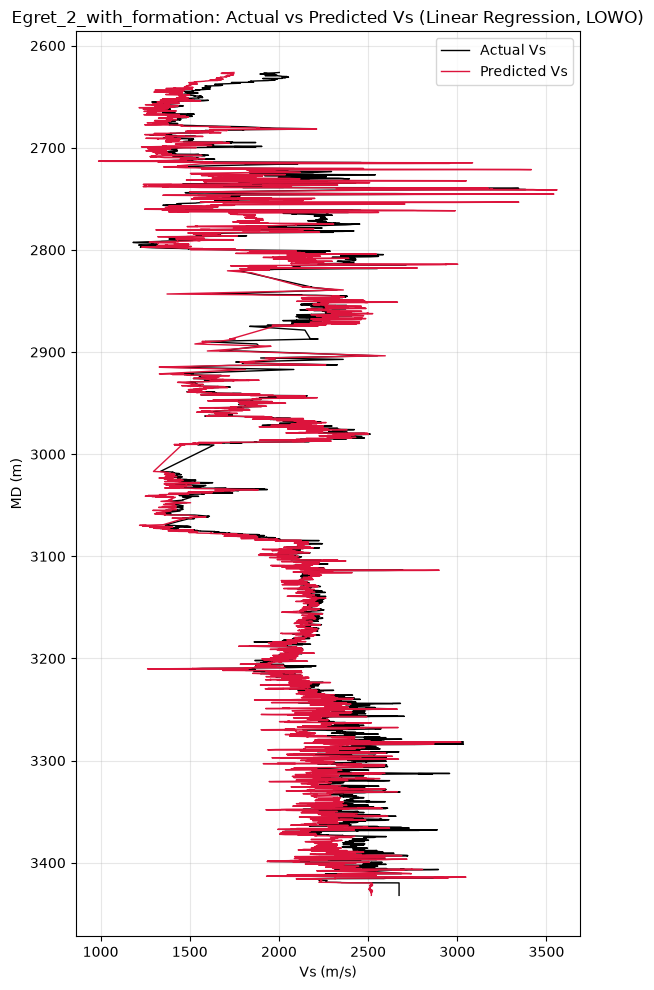

Egret_2_with_formation  R²=0.773  RMSE=181.4 m/s


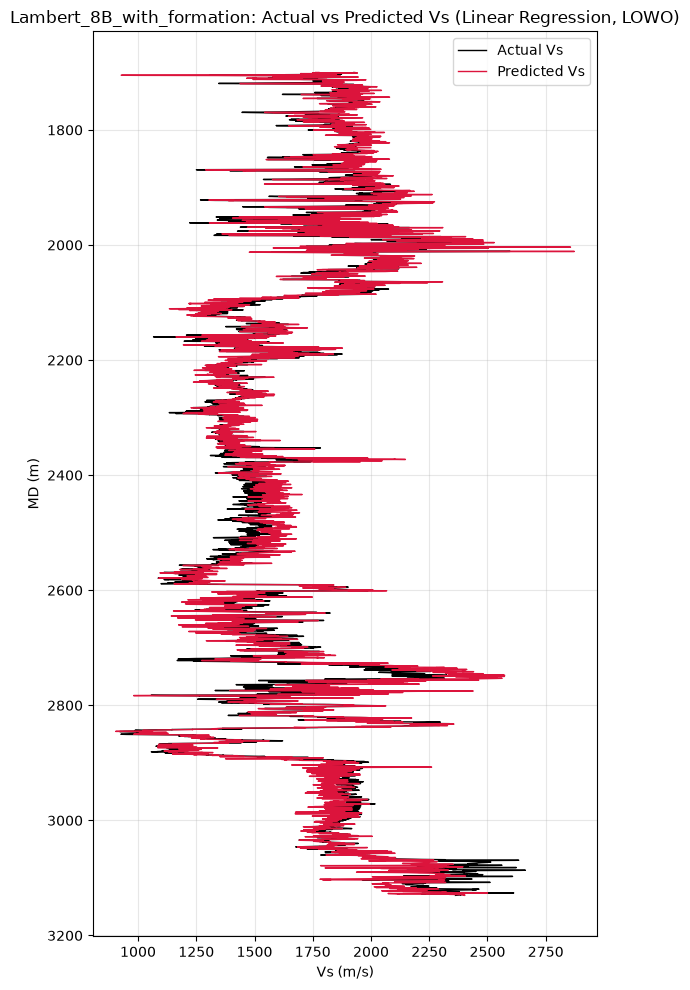

Lambert_8B_with_formation  R²=0.901  RMSE=93.7 m/s


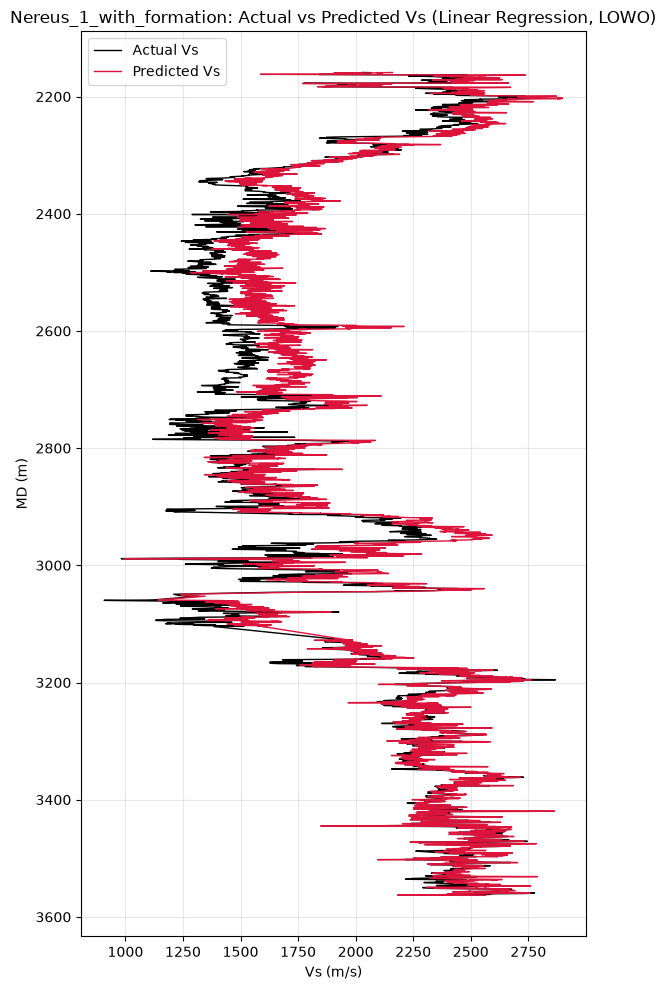

Nereus_1_with_formation  R²=0.878  RMSE=154.9 m/s


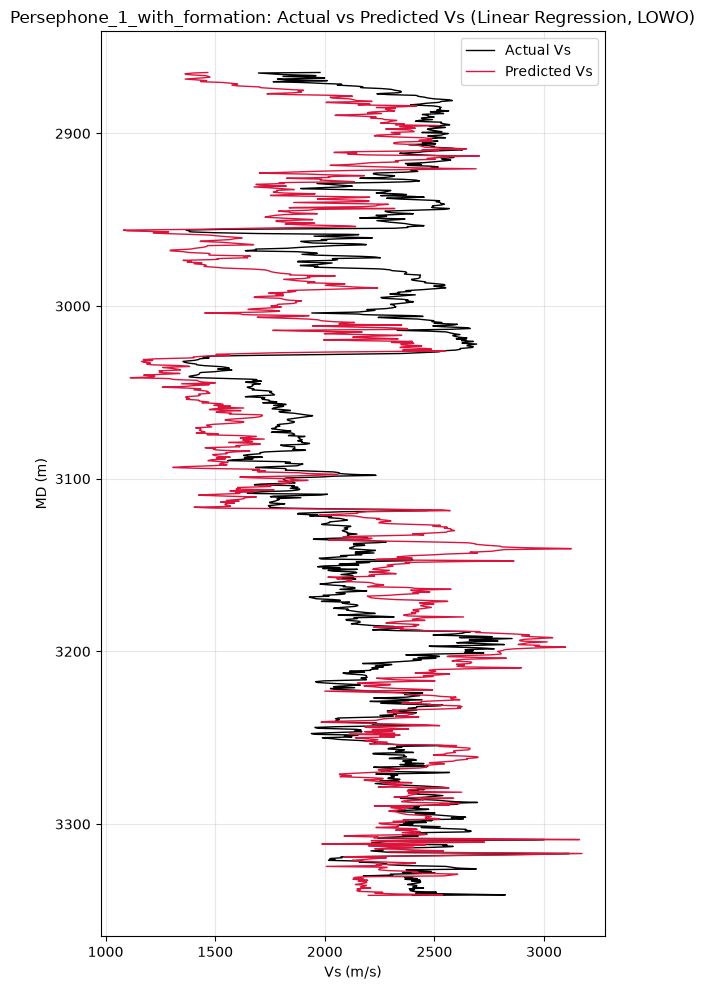

Persephone_1_with_formation  R²=-0.086  RMSE=316.4 m/s


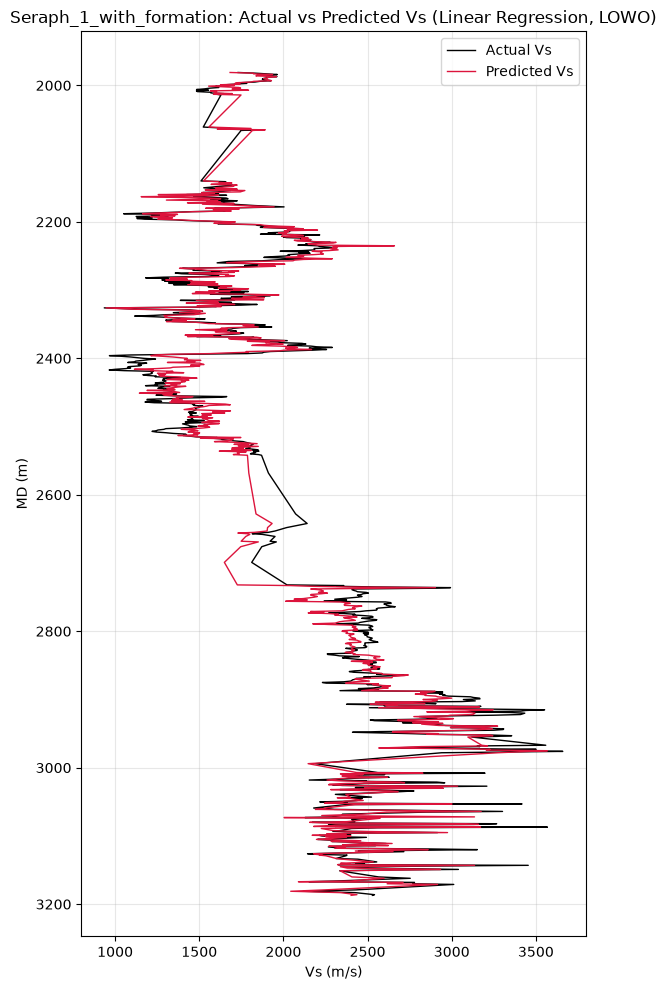

Seraph_1_with_formation  R²=0.946  RMSE=134.7 m/s


In [13]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    model = LinearRegression()
    model.fit(train_df[features_reg], train_df[target_reg])

    val_df['VS_PRED'] = model.predict(val_df[features_reg])

    plt.figure(figsize=(6, 10))
    plt.plot(val_df[target_reg], val_df['MD'], label='Actual Vs', color='black', lw=1)
    plt.plot(val_df['VS_PRED'], val_df['MD'], label='Predicted Vs', color='crimson', lw=1)
    plt.gca().invert_yaxis()
    plt.xlabel('Vs (m/s)')
    plt.ylabel('MD (m)')
    plt.title(f'{plot_well}: Actual vs Predicted Vs (Linear Regression, LOWO)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"linear_actual_vs_predicted_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

    r2 = r2_score(val_df[target_reg], val_df['VS_PRED'])
    rmse = np.sqrt(mean_squared_error(val_df[target_reg], val_df['VS_PRED']))
    print(f"{plot_well}  R²={r2:.3f}  RMSE={rmse:.1f} m/s")

### Diagnostic plot — multi-track well log display, for every measured well

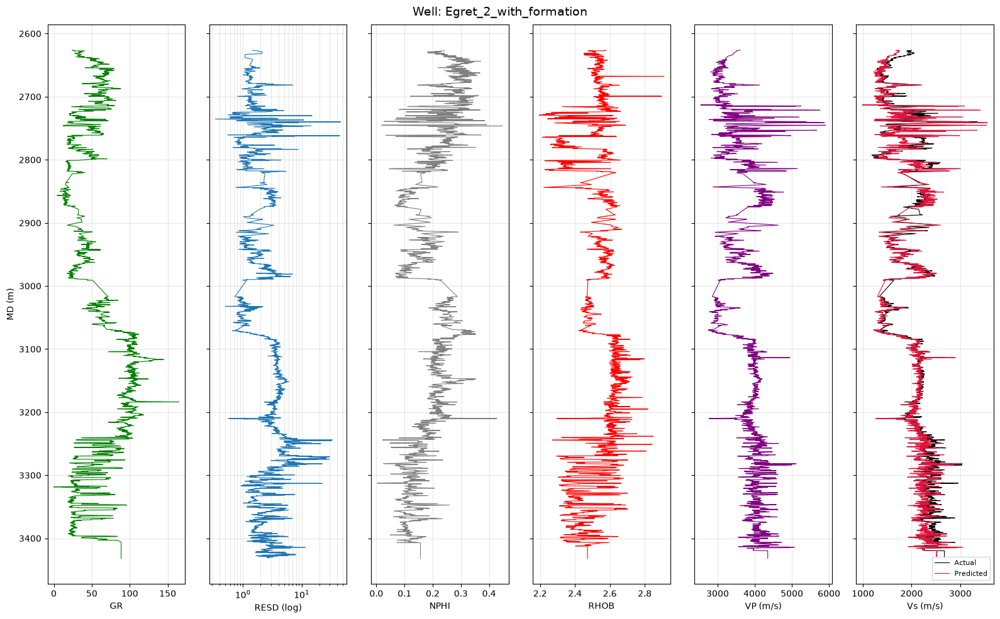

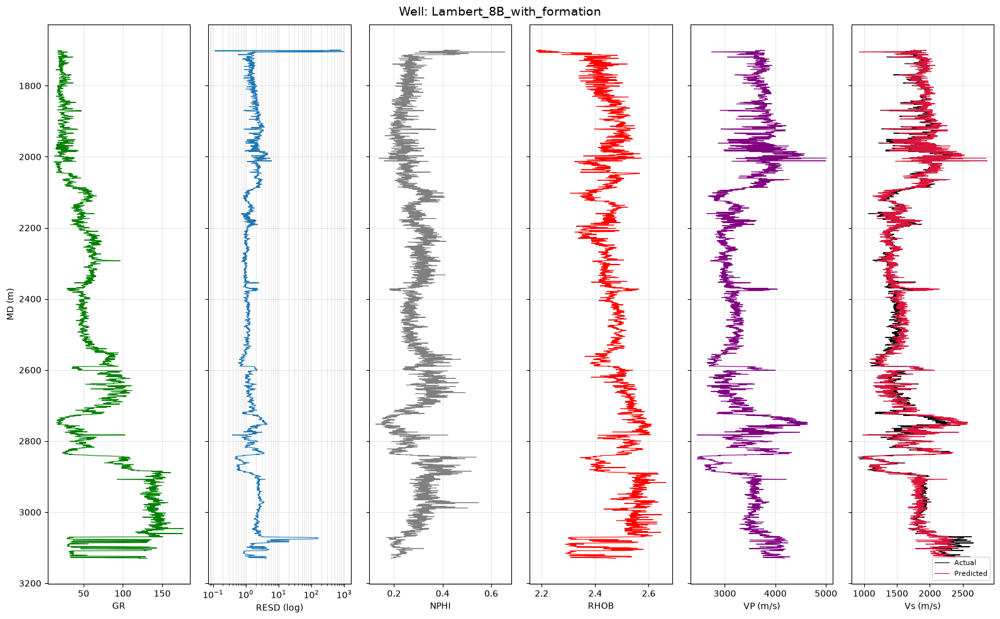

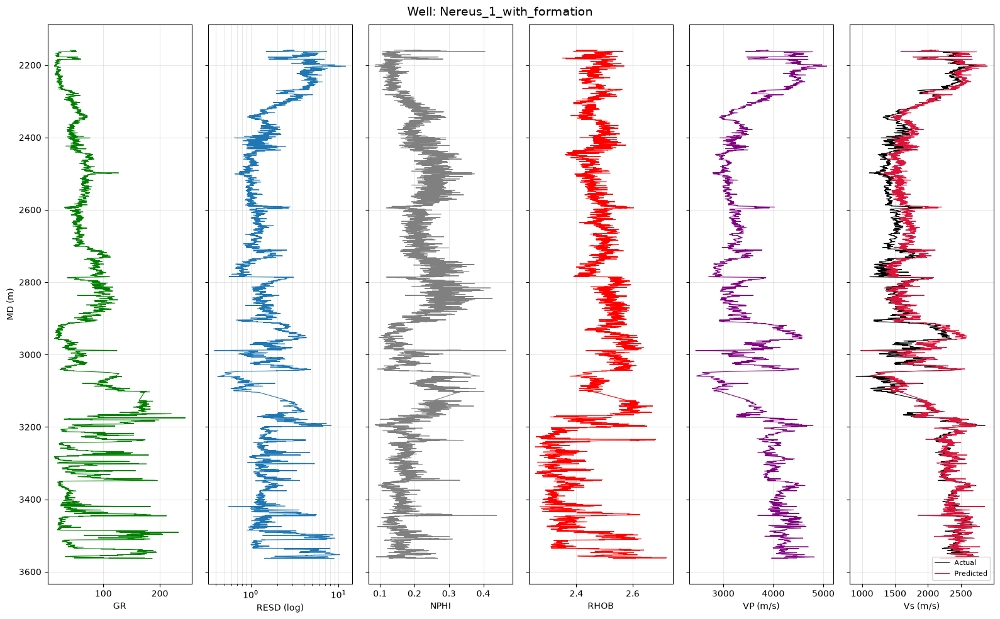

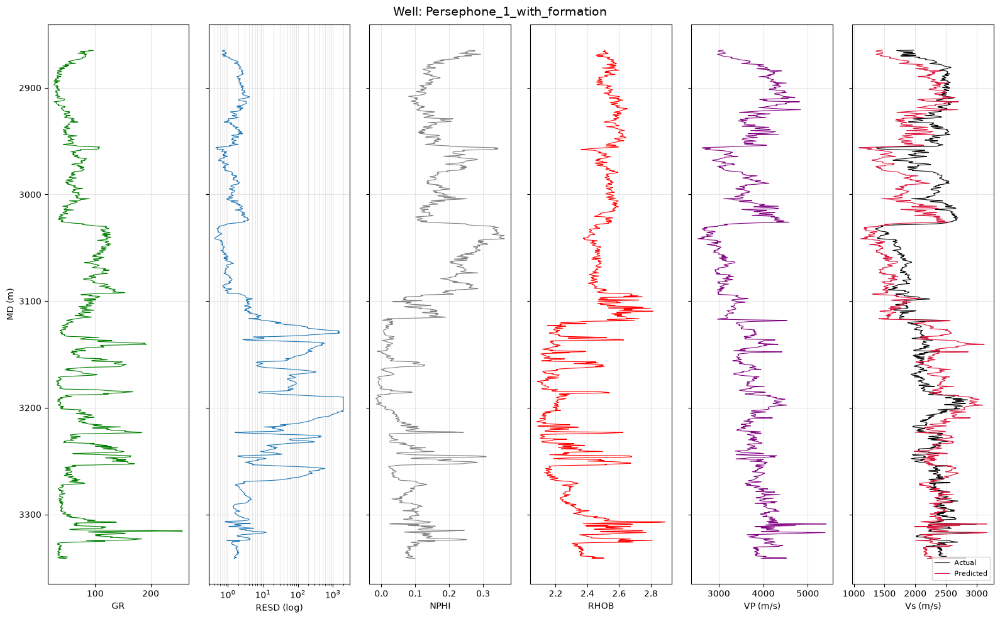

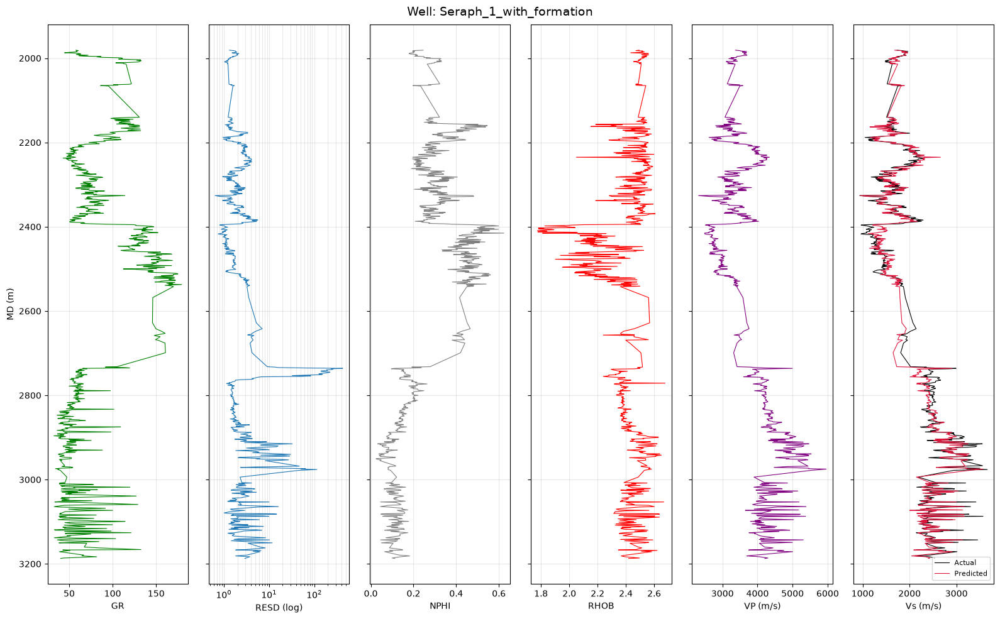

In [14]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    model = LinearRegression()
    model.fit(train_df[features_reg], train_df[target_reg])
    val_df['VS_PRED'] = model.predict(val_df[features_reg])

    depth = val_df['MD']

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(16, 10), sharey=True)

    # Track 1 - GR
    axes[0].plot(val_df['GR_EDITED'], depth, color='green', lw=0.8)
    axes[0].set_xlabel('GR')
    axes[0].grid(alpha=0.3)

    # Track 2 - Resistivity (log scale is standard convention for resistivity)
    axes[1].plot(val_df['RESD_EDITED'], depth, color='tab:blue', lw=0.8)
    axes[1].set_xscale('log')
    axes[1].set_xlabel('RESD (log)')
    axes[1].grid(alpha=0.3, which='both')

    # Track 3 - NPHI (neutron porosity)
    axes[2].plot(val_df['NPHI_EDITED'], depth, color='gray', lw=0.8)
    axes[2].set_xlabel('NPHI')
    axes[2].grid(alpha=0.3)

    # Track 4 - RHOB (density)
    axes[3].plot(val_df['RHOB_EDITED'], depth, color='red', lw=0.8)
    axes[3].set_xlabel('RHOB')
    axes[3].grid(alpha=0.3)

    # Track 5 - VP (compressional velocity, strongest predictor)
    axes[4].plot(val_df['VP_EDITED'], depth, color='purple', lw=0.8)
    axes[4].set_xlabel('VP (m/s)')
    axes[4].grid(alpha=0.3)

    # Track 6 - Actual vs Predicted Vs
    axes[5].plot(val_df[target_reg], depth, color='black', lw=0.8, label='Actual')
    axes[5].plot(val_df['VS_PRED'], depth, color='crimson', lw=0.8, label='Predicted')
    axes[5].set_xlabel('Vs (m/s)')
    axes[5].legend(fontsize=8, loc='lower right')
    axes[5].grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel('MD (m)')
    fig.suptitle(f'Well: {plot_well}', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"linear_multitrack_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

### Residual diagnostics (Linear Regression, pooled across 5 wells)

Residual (predicted minus actual) plotted against actual Vs and against depth -- checks for bias that a single averaged R²/RMSE can hide, e.g. systematic under/over-prediction at particular Vs ranges or depths.

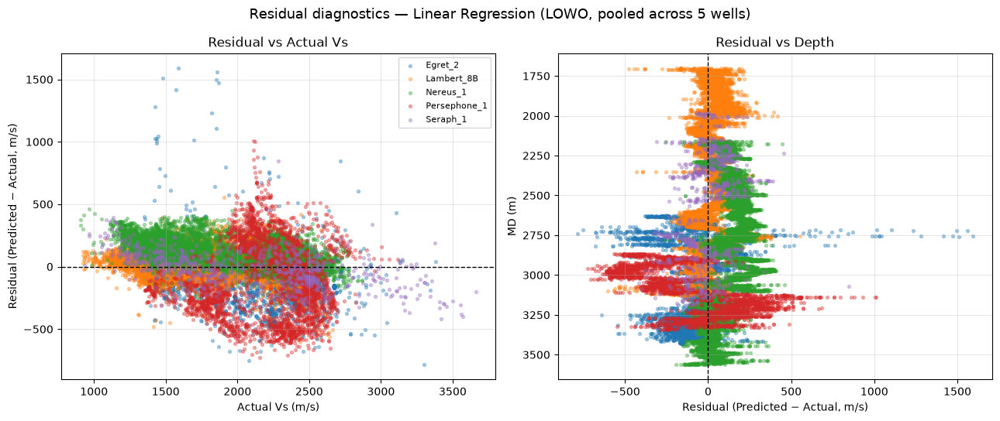

Mean residual: 19.66 m/s   Std residual: 168.82 m/s


In [15]:
actual_all, predicted_all, depth_all, well_all = [], [], [], []

for val_well in measured_wells:
    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    model = LinearRegression()
    model.fit(train_df[features_reg], train_df[target_reg])
    pred = model.predict(val_df[features_reg])

    actual_all.extend(val_df[target_reg].values)
    predicted_all.extend(pred)
    depth_all.extend(val_df['MD'].values)
    well_all.extend([val_well.replace('_with_formation', '')] * len(val_df))

resid_df = pd.DataFrame({'Actual': actual_all, 'Predicted': predicted_all, 'Depth': depth_all, 'Well': well_all})
resid_df['Residual'] = resid_df['Predicted'] - resid_df['Actual']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for well_name, group in resid_df.groupby('Well'):
    axes[0].scatter(group['Actual'], group['Residual'], s=8, alpha=0.35, label=well_name)
axes[0].axhline(0, color='black', lw=1, ls='--')
axes[0].set_xlabel('Actual Vs (m/s)')
axes[0].set_ylabel('Residual (Predicted − Actual, m/s)')
axes[0].set_title('Residual vs Actual Vs')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for well_name, group in resid_df.groupby('Well'):
    axes[1].scatter(group['Residual'], group['Depth'], s=8, alpha=0.35, label=well_name)
axes[1].axvline(0, color='black', lw=1, ls='--')
axes[1].invert_yaxis()
axes[1].set_xlabel('Residual (Predicted − Actual, m/s)')
axes[1].set_ylabel('MD (m)')
axes[1].set_title('Residual vs Depth')
axes[1].grid(alpha=0.3)

fig.suptitle('Residual diagnostics — Linear Regression (LOWO, pooled across 5 wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "linear_residual_diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean residual: {resid_df['Residual'].mean():.2f} m/s   Std residual: {resid_df['Residual'].std():.2f} m/s")


## 7. Ridge Regression — LOWO cross-validation (5 measured wells)

Same fold structure as Section 6 — train on the other 4 measured wells, test on the held-out one. `alpha=1.0` is used directly below — an alpha sweep tested earlier (0.001 to 10,000) showed almost no difference from plain linear regression, since the main source of multicollinearity (VCL/ILLITE) was already removed in Section 4, so the sweep is skipped here to keep things quick.

In [16]:
results = []

for val_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    model = Ridge(alpha=1.0)
    model.fit(train_df[features_reg], train_df[target_reg])

    pred = model.predict(val_df[features_reg])

    results.append({
        'Validation Well': val_well,
        'R2': r2_score(val_df[target_reg], pred),
        'RMSE': np.sqrt(mean_squared_error(val_df[target_reg], pred)),
        'MAE': mean_absolute_error(val_df[target_reg], pred)
    })

results_ridge = pd.DataFrame(results)
results_ridge['Model'] = 'Ridge Regression'
results_ridge = results_ridge[['Model', 'Validation Well', 'R2', 'RMSE', 'MAE']]
results_ridge.to_csv(RESULTS_DIR / 'lowo_ridge_regression.csv', index=False)

print("Mean R2:", results_ridge['R2'].mean())
print("Mean RMSE:", results_ridge['RMSE'].mean())
print("Mean MAE:", results_ridge['MAE'].mean())

results_ridge

Mean R2: 0.6844280619963292
Mean RMSE: 175.79692299572474
Mean MAE: 139.01564451817632


,Model,Validation Well,R2,RMSE,MAE
0,Ridge Regression,Egret_2_with_formation,0.772701,181.449108,122.366761
1,Ridge Regression,Lambert_8B_with_formation,0.901381,93.632847,69.836262
2,Ridge Regression,Nereus_1_with_formation,0.879725,154.082250,128.163874
3,Ridge Regression,Persephone_1_with_formation,-0.077654,315.197877,270.403540
4,Ridge Regression,Seraph_1_with_formation,0.945987,134.622533,104.307785


### Residual diagnostics (Ridge Regression, pooled across 5 wells)

Residual (predicted minus actual) plotted against actual Vs and against depth -- checks for bias that a single averaged R²/RMSE can hide, e.g. systematic under/over-prediction at particular Vs ranges or depths.

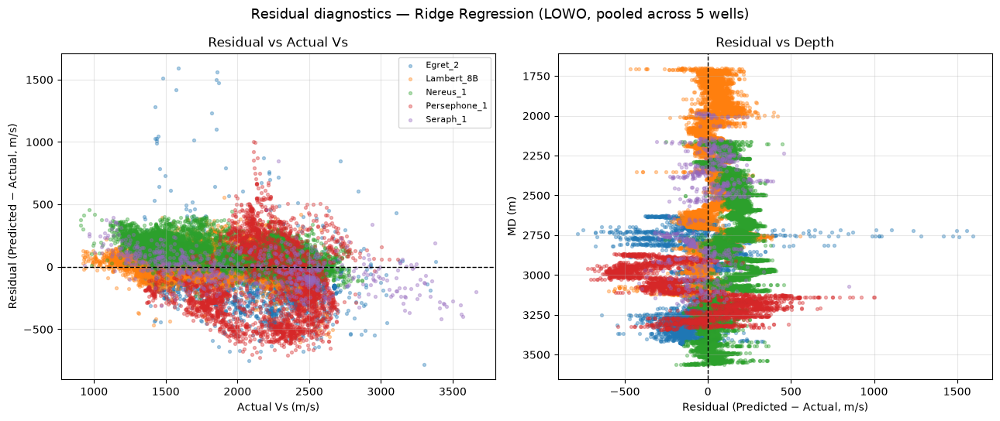

Mean residual: 19.75 m/s   Std residual: 168.29 m/s


In [17]:
actual_all, predicted_all, depth_all, well_all = [], [], [], []

for val_well in measured_wells:
    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    model = Ridge(alpha=1.0)
    model.fit(train_df[features_reg], train_df[target_reg])
    pred = model.predict(val_df[features_reg])

    actual_all.extend(val_df[target_reg].values)
    predicted_all.extend(pred)
    depth_all.extend(val_df['MD'].values)
    well_all.extend([val_well.replace('_with_formation', '')] * len(val_df))

resid_df = pd.DataFrame({'Actual': actual_all, 'Predicted': predicted_all, 'Depth': depth_all, 'Well': well_all})
resid_df['Residual'] = resid_df['Predicted'] - resid_df['Actual']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for well_name, group in resid_df.groupby('Well'):
    axes[0].scatter(group['Actual'], group['Residual'], s=8, alpha=0.35, label=well_name)
axes[0].axhline(0, color='black', lw=1, ls='--')
axes[0].set_xlabel('Actual Vs (m/s)')
axes[0].set_ylabel('Residual (Predicted − Actual, m/s)')
axes[0].set_title('Residual vs Actual Vs')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for well_name, group in resid_df.groupby('Well'):
    axes[1].scatter(group['Residual'], group['Depth'], s=8, alpha=0.35, label=well_name)
axes[1].axvline(0, color='black', lw=1, ls='--')
axes[1].invert_yaxis()
axes[1].set_xlabel('Residual (Predicted − Actual, m/s)')
axes[1].set_ylabel('MD (m)')
axes[1].set_title('Residual vs Depth')
axes[1].grid(alpha=0.3)

fig.suptitle('Residual diagnostics — Ridge Regression (LOWO, pooled across 5 wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ridge_residual_diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean residual: {resid_df['Residual'].mean():.2f} m/s   Std residual: {resid_df['Residual'].std():.2f} m/s")


## 8. Lasso Regression — LOWO cross-validation (5 measured wells)



Best alpha by mean LOWO RMSE: 7.2790  (RMSE=170.84, R2=0.7130)


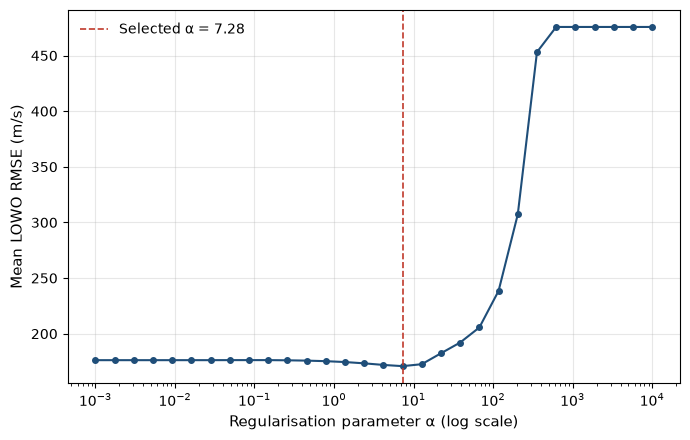

In [18]:
alphas = np.logspace(-3, 4, 30)  # 0.001 to 10,000

sweep_results = []

for alpha in alphas:
    fold_rmse = []
    fold_r2 = []

    for val_well in measured_wells:
        train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
        val_df = data_df[data_df['Well Name'] == val_well]

        scaler = StandardScaler()
        X_train = scaler.fit_transform(train_df[features_reg])
        X_val = scaler.transform(val_df[features_reg])

        model = Lasso(alpha=alpha, max_iter=20000, tol=1e-3)
        model.fit(X_train, train_df[target_reg])
        pred = model.predict(X_val)

        fold_rmse.append(np.sqrt(mean_squared_error(val_df[target_reg], pred)))
        fold_r2.append(r2_score(val_df[target_reg], pred))

    sweep_results.append({
        'alpha': alpha,
        'mean_rmse': np.mean(fold_rmse),
        'mean_r2': np.mean(fold_r2)
    })

sweep_df = pd.DataFrame(sweep_results)

best_row = sweep_df.loc[sweep_df['mean_rmse'].idxmin()]
print(f"Best alpha by mean LOWO RMSE: {best_row['alpha']:.4f}  (RMSE={best_row['mean_rmse']:.2f}, R2={best_row['mean_r2']:.4f})")

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(sweep_df['alpha'], sweep_df['mean_rmse'], marker='o', ms=4, color='#1f4e79')
ax.axvline(best_row['alpha'], color='#c0392b', ls='--', lw=1.2,
           label=f"Selected α = {best_row['alpha']:.2f}")
ax.set_xscale('log')
ax.set_xlabel('Regularisation parameter α (log scale)', fontsize=11)
ax.set_ylabel('Mean LOWO RMSE (m/s)', fontsize=11)
ax.legend(fontsize=10, frameon=False)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "lasso_alpha_sweep.png", dpi=300, bbox_inches='tight')
plt.show()

### Final Lasso model (alpha = best_alpha, from the sweep above)

In [19]:
best_alpha = best_row['alpha']   

results = []

for val_well in measured_wells:
    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)
    model.fit(X_train, train_df[target_reg])
    pred = model.predict(X_val)

    results.append({
        'Validation Well': val_well,
        'R2': r2_score(val_df[target_reg], pred),
        'RMSE': np.sqrt(mean_squared_error(val_df[target_reg], pred)),
        'MAE': mean_absolute_error(val_df[target_reg], pred)
    })

results_lasso = pd.DataFrame(results)
results_lasso['Model'] = 'Lasso Regression'
results_lasso = results_lasso[['Model', 'Validation Well', 'R2', 'RMSE', 'MAE']]
results_lasso.to_csv(RESULTS_DIR / 'lowo_lasso_regression.csv', index=False)

print("Mean R2:", results_lasso['R2'].mean())
print("Mean RMSE:", results_lasso['RMSE'].mean())
results_lasso

Mean R2: 0.7130023973718661
Mean RMSE: 170.83619633514465


,Model,Validation Well,R2,RMSE,MAE
0,Lasso Regression,Egret_2_with_formation,0.775797,180.208993,120.732231
1,Lasso Regression,Lambert_8B_with_formation,0.882234,102.319476,79.041855
2,Lasso Regression,Nereus_1_with_formation,0.887996,148.690002,125.001683
3,Lasso Regression,Persephone_1_with_formation,0.069397,292.904370,243.492383
4,Lasso Regression,Seraph_1_with_formation,0.949588,130.058140,102.824136


### Check: are Lasso errors bigger in washouts?

Table 6 is the fair test: in-gauge vs washed-out depths **inside the same formation**, so only the hole condition differs. Used for the washout decision in Section 2b.

In [20]:
# --- Are Lasso errors bigger in washouts? (uses the caliper flags from Section 2c) ---
# Same LOWO as above (train on 4 measured wells, predict the 5th), but keeping the error at every depth
parts = []
for val_well in measured_wells:
    tr = data_df[(data_df['Well Name'] != val_well) & data_df['Well Name'].isin(measured_wells)]
    va = data_df[data_df['Well Name'] == val_well].copy()
    sc = StandardScaler().fit(tr[features_reg])
    mdl = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3).fit(sc.transform(tr[features_reg]), tr[target_reg])
    va['error'] = va[target_reg] - mdl.predict(sc.transform(va[features_reg]))   # + = model predicts too LOW
    parts.append(va[['error']])

res = pd.concat(parts).join(m[['Well', 'Formation', 'washout', 'cali_bad']])     # matched row by row
res['hole'] = np.select([res['cali_bad'], res['washout']], ['no caliper', 'washout'], default='in gauge')

def rmse(x):
    return np.sqrt(np.mean(np.square(x)))

def table(keys):
    t = res.groupby(keys + ['hole'])['error'].agg(rows='size', RMSE=rmse, mean_error='mean').unstack('hole')
    t.columns = [f'{stat} ({hole})' for stat, hole in t.columns]
    return t.round(1)

# Table 5: per well, error in good hole vs washout
print("Table 5 - Lasso LOWO error per well: in-gauge hole vs washout (m/s)")
display(table(['Well']))

# Table 6: same comparison inside the same formation (same rock, so only the hole condition differs)
t6 = table(['Well', 'Formation'])
t6 = t6[(t6['rows (washout)'] >= 20) & (t6['rows (in gauge)'] >= 20)]
print("\nTable 6 - same formation, in-gauge vs washout (formations with at least 20 depths of each)")
display(t6)


Table 5 - Lasso LOWO error per well: in-gauge hole vs washout (m/s)


,rows (in gauge),rows (no caliper),rows (washout),RMSE (in gauge),RMSE (no caliper),RMSE (washout),mean_error (in gauge),mean_error (no caliper),mean_error (washout)
Well,,,,,,,,,
Egret_2,3494.0,149.0,863.0,155.3,171.2,258.6,56.1,116.1,107.6
Lambert_8B,9344.0,2.0,39.0,102.4,21.7,93.9,-42.3,21.7,36.3
Nereus_1,8947.0,NaN,NaN,148.7,NaN,NaN,-94.1,NaN,NaN
Persephone_1,3126.0,NaN,2.0,293.0,NaN,11.0,163.8,NaN,11.0
Seraph_1,692.0,NaN,91.0,126.8,NaN,152.7,32.3,NaN,-52.1



Table 6 - same formation, in-gauge vs washout (formations with at least 20 depths of each)


rows (in gauge)  rows (no caliper)  \
Well       Formation                                                  
Egret_2    Toolonga Calcilutite             69.0                NaN   
           Withnell Fm                     539.0                NaN   
Lambert_8B Delambre/Mandu Fms             2014.0                NaN   
Seraph_1   Muderong Shale                   75.0                NaN   

                                 rows (washout)  RMSE (in gauge)  \
Well       Formation                                               
Egret_2    Toolonga Calcilutite           161.0            149.7   
           Withnell Fm                    564.0            264.0   
Lambert_8B Delambre/Mandu Fms              39.0            111.4   
Seraph_1   Muderong Shale                  72.0             98.5   

                                 RMSE (no caliper)  RMSE (washout)  \
Well       Formation                                                 
Egret_2    Toolonga Calcilutite                NaN           152.1   
           Withnell Fm                         NaN           291.4   
Lambert_8B Delambre/Mandu Fms                  NaN            93.9   
Seraph_1   Muderong Shale                      NaN           140.3   

                                 mean_error (in gauge)  \
Well       Formation                                     
Egret_2    Toolonga Calcilutite                 -125.7   
           Withnell Fm                             2.9   
Lambert_8B Delambre/Mandu Fms                    -86.8   
Seraph_1   Muderong Shale                        -21.9   

                                 mean_error (no caliper)  mean_error (washout)  
Well       Formation                                                            
Egret_2    Toolonga Calcilutite                      NaN                 -35.2  
           Withnell Fm                               NaN                 129.8  
Lambert_8B Delambre/Mandu Fms                        NaN                  36.3  
Seraph_1   Muderong Shale                            NaN                 -90.1

### Coefficient inspection at the chosen alpha

In [21]:
measured_df = data_df[data_df['Well Name'].isin(measured_wells)]

scaler_full = StandardScaler()
X_full = scaler_full.fit_transform(measured_df[features_reg])

model_full = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)
model_full.fit(X_full, measured_df[target_reg])

coef_df = pd.DataFrame({
    'Feature': features_reg,
    'Coefficient': model_full.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

coef_df

,Feature,Coefficient
4,VP_EDITED,351.318443
2,NPHI_EDITED,-57.722587
0,GR_EDITED,43.503042
1,RHOB_EDITED,-40.878091
3,RESD_LOG,0.000000


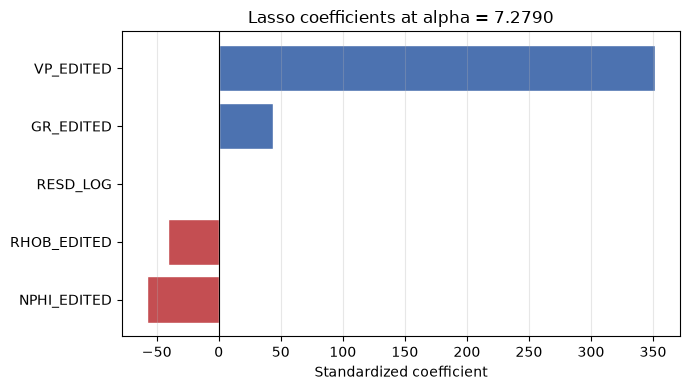

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
coef_plot = coef_df.sort_values('Coefficient')
colors = ['#C44E52' if v < 0 else '#4C72B0' for v in coef_plot['Coefficient']]
ax.barh(coef_plot['Feature'], coef_plot['Coefficient'], color=colors, edgecolor='white')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Standardized coefficient')
ax.set_title(f'Lasso coefficients at alpha = {best_alpha:.4f}')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "lasso_coefficients_bar.png", dpi=300, bbox_inches='tight')
plt.show()


### Diagnostic plot — multi-track well log display, for every measured well

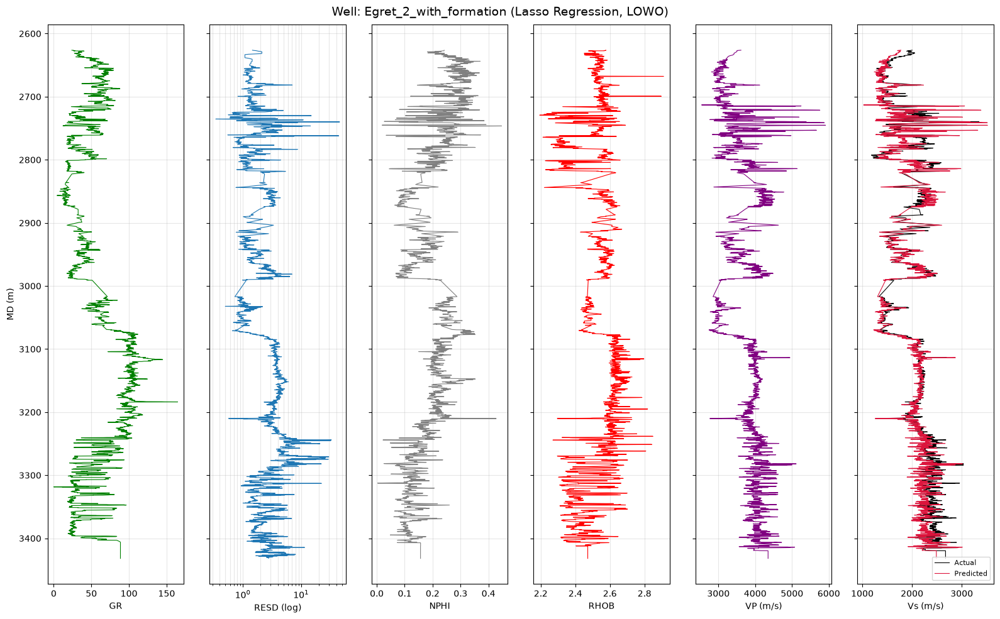

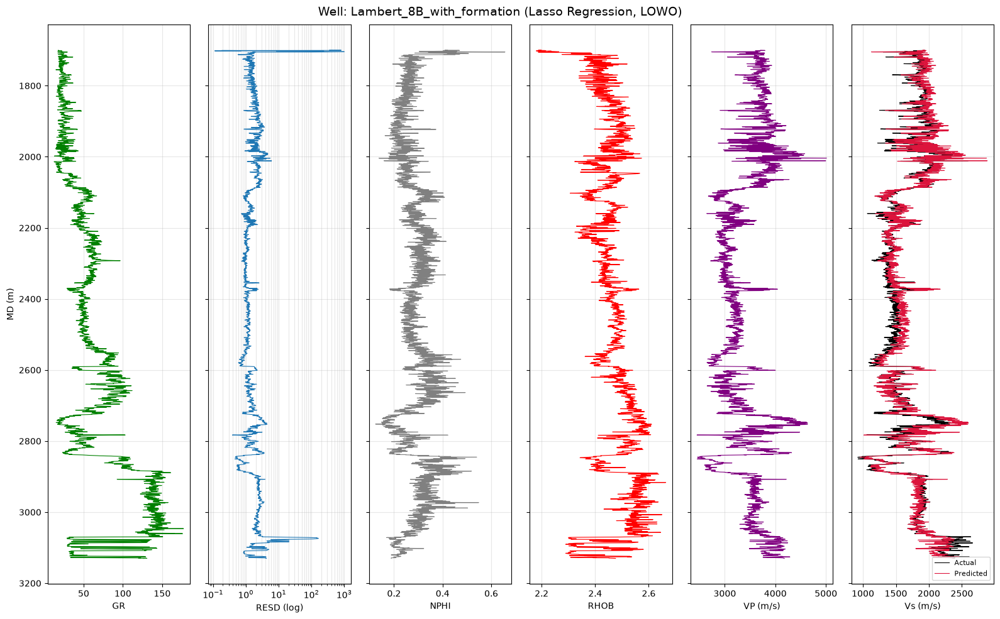

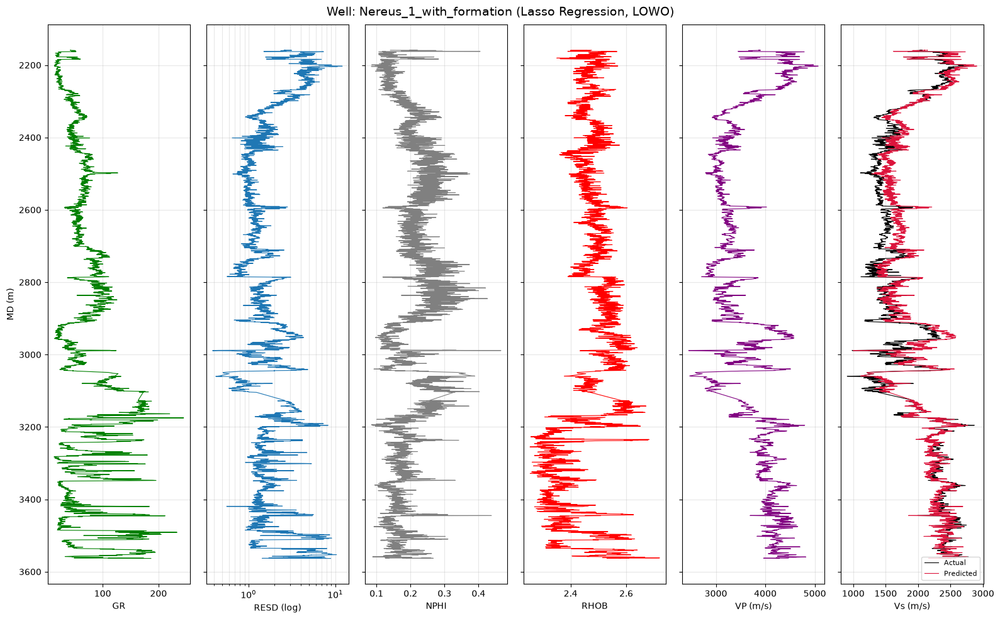

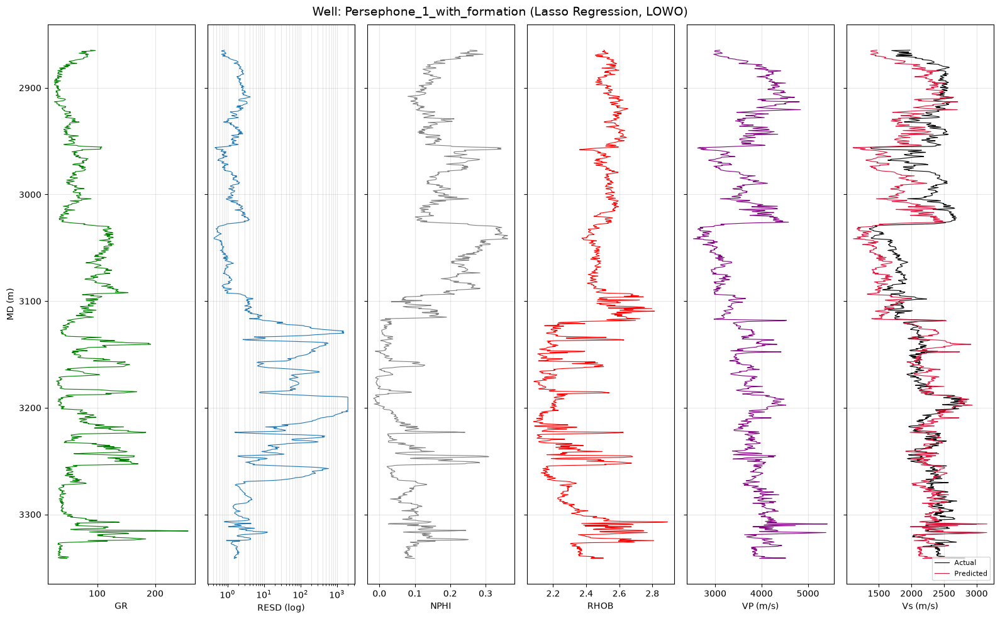

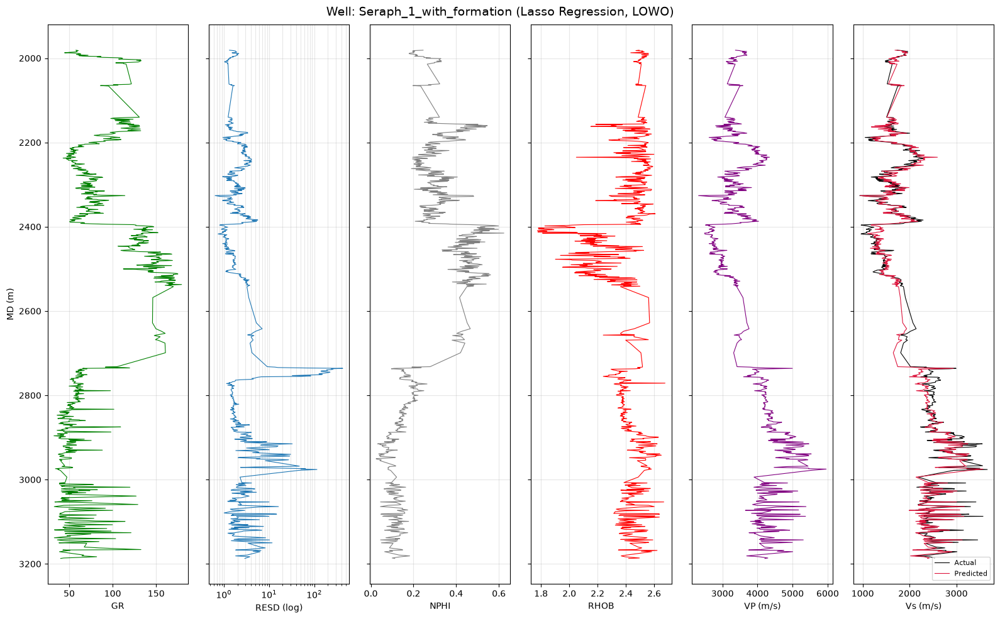

In [23]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)
    model.fit(X_train, train_df[target_reg])
    val_df['VS_PRED'] = model.predict(X_val)

    depth = val_df['MD']

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(16, 10), sharey=True)

    # Track 1 - GR
    axes[0].plot(val_df['GR_EDITED'], depth, color='green', lw=0.8)
    axes[0].set_xlabel('GR')
    axes[0].grid(alpha=0.3)

    # Track 2 - Resistivity (log scale is standard convention for resistivity)
    axes[1].plot(val_df['RESD_EDITED'], depth, color='tab:blue', lw=0.8)
    axes[1].set_xscale('log')
    axes[1].set_xlabel('RESD (log)')
    axes[1].grid(alpha=0.3, which='both')

    # Track 3 - NPHI (neutron porosity)
    axes[2].plot(val_df['NPHI_EDITED'], depth, color='gray', lw=0.8)
    axes[2].set_xlabel('NPHI')
    axes[2].grid(alpha=0.3)

    # Track 4 - RHOB (density)
    axes[3].plot(val_df['RHOB_EDITED'], depth, color='red', lw=0.8)
    axes[3].set_xlabel('RHOB')
    axes[3].grid(alpha=0.3)

    # Track 5 - VP (compressional velocity, strongest predictor)
    axes[4].plot(val_df['VP_EDITED'], depth, color='purple', lw=0.8)
    axes[4].set_xlabel('VP (m/s)')
    axes[4].grid(alpha=0.3)

    # Track 6 - Actual vs Predicted Vs
    axes[5].plot(val_df[target_reg], depth, color='black', lw=0.8, label='Actual')
    axes[5].plot(val_df['VS_PRED'], depth, color='crimson', lw=0.8, label='Predicted')
    axes[5].set_xlabel('Vs (m/s)')
    axes[5].legend(fontsize=8, loc='lower right')
    axes[5].grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel('MD (m)')
    fig.suptitle(f'Well: {plot_well} (Lasso Regression, LOWO)', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"lasso_multitrack_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

### Residual diagnostics (Lasso Regression, pooled across 5 wells)

Residual (predicted minus actual) plotted against actual Vs and against depth -- checks for bias that a single averaged R²/RMSE can hide, e.g. systematic under/over-prediction at particular Vs ranges or depths.

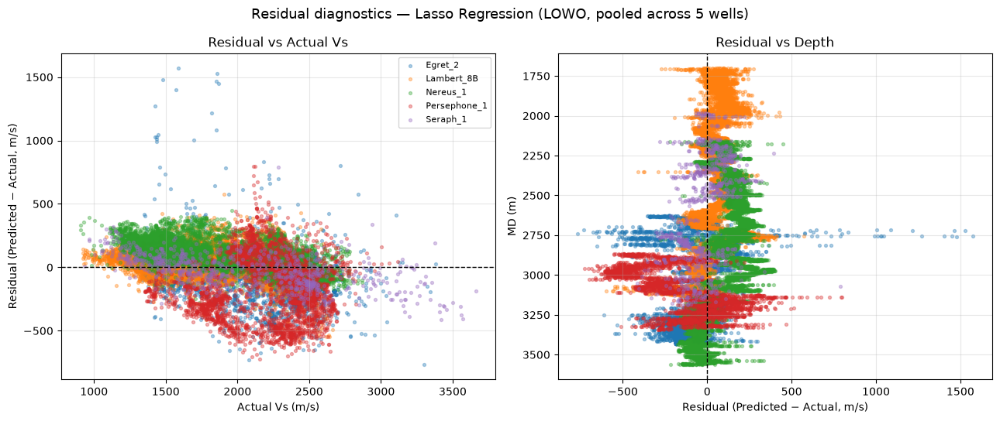

Mean residual: 14.96 m/s   Std residual: 163.84 m/s


In [24]:
actual_all, predicted_all, depth_all, well_all = [], [], [], []

for val_well in measured_wells:
    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)
    model.fit(X_train, train_df[target_reg])
    pred = model.predict(X_val)

    actual_all.extend(val_df[target_reg].values)
    predicted_all.extend(pred)
    depth_all.extend(val_df['MD'].values)
    well_all.extend([val_well.replace('_with_formation', '')] * len(val_df))

resid_df = pd.DataFrame({'Actual': actual_all, 'Predicted': predicted_all, 'Depth': depth_all, 'Well': well_all})
resid_df['Residual'] = resid_df['Predicted'] - resid_df['Actual']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for well_name, group in resid_df.groupby('Well'):
    axes[0].scatter(group['Actual'], group['Residual'], s=8, alpha=0.35, label=well_name)
axes[0].axhline(0, color='black', lw=1, ls='--')
axes[0].set_xlabel('Actual Vs (m/s)')
axes[0].set_ylabel('Residual (Predicted − Actual, m/s)')
axes[0].set_title('Residual vs Actual Vs')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for well_name, group in resid_df.groupby('Well'):
    axes[1].scatter(group['Residual'], group['Depth'], s=8, alpha=0.35, label=well_name)
axes[1].axvline(0, color='black', lw=1, ls='--')
axes[1].invert_yaxis()
axes[1].set_xlabel('Residual (Predicted − Actual, m/s)')
axes[1].set_ylabel('MD (m)')
axes[1].set_title('Residual vs Depth')
axes[1].grid(alpha=0.3)

fig.suptitle('Residual diagnostics — Lasso Regression (LOWO, pooled across 5 wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "lasso_residual_diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean residual: {resid_df['Residual'].mean():.2f} m/s   Std residual: {resid_df['Residual'].std():.2f} m/s")


### Explainable AI — SHAP values for Lasso Regression

SHAP (SHapley Additive exPlanations) breaks each individual prediction down into a contribution from each input feature, using Shapley values from cooperative game theory. The coefficient table above (Section 8, "Coefficient inspection") gives one global number per feature, averaged across the whole dataset — SHAP instead gives a value **per depth point, per feature**, so it's possible to see exactly which log pushed the prediction up or down at a specific depth, not just on average.


In [25]:
import shap

# Use the final Lasso model fit on all 5 measured wells (model_full / X_full).
# Full dataset as background, so the SHAP zero-point uses the true feature means.
masker = shap.maskers.Independent(X_full, max_samples=len(X_full))
explainer = shap.LinearExplainer(model_full, masker)
shap_values = explainer.shap_values(X_full)

print("SHAP values shape:", shap_values.shape)   # (n_samples, n_features)

# Sanity check: SHAP values + baseline should equal the model's predictions exactly
print("Check:", np.allclose(shap_values.sum(axis=1) + explainer.expected_value, model_full.predict(X_full)))

SHAP values shape: (26749, 5)
Check: True


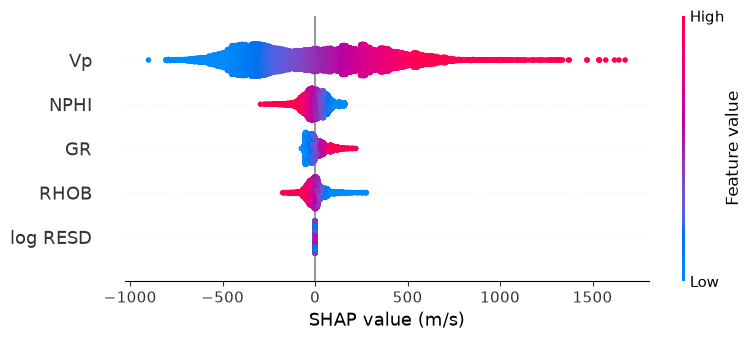

In [26]:
nice = {'GR_EDITED': 'GR', 'RHOB_EDITED': 'RHOB', 'NPHI_EDITED': 'NPHI',
        'RESD_LOG': 'log RESD', 'VP_EDITED': 'Vp'}

shap.summary_plot(shap_values, X_full, feature_names=[nice[f] for f in features_reg], show=False)
plt.xlabel('SHAP value (m/s)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary_lasso.png", dpi=300, bbox_inches='tight')
plt.show()

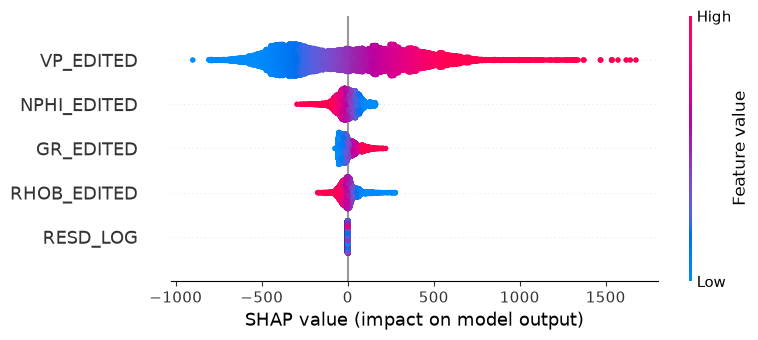

In [27]:
shap.summary_plot(shap_values, X_full, feature_names=features_reg, show=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary_lasso.png", dpi=300, bbox_inches='tight')
plt.show()

#### SHAP values along depth, per well

Mean |SHAP| per feature (m/s of Vs):


,GR_EDITED,RHOB_EDITED,NPHI_EDITED,RESD_LOG,VP_EDITED
Well,,,,,
Egret_2,32.0,42.0,43.0,0.0,311.0
Lambert_8B,37.0,21.0,46.0,0.0,259.0
Nereus_1,34.0,25.0,34.0,0.0,335.0
Persephone_1,32.0,55.0,75.0,0.0,271.0
Seraph_1,35.0,45.0,80.0,0.0,428.0
All wells,35.0,30.0,46.0,0.0,299.0


Share of total contribution (%):


,GR_EDITED,RHOB_EDITED,NPHI_EDITED,RESD_LOG,VP_EDITED
Well,,,,,
Egret_2,7.4,9.8,10.1,0.0,72.8
Lambert_8B,10.1,5.7,12.8,0.0,71.4
Nereus_1,8.0,5.9,7.8,0.0,78.2
Persephone_1,7.5,12.6,17.4,0.0,62.5
Seraph_1,5.9,7.6,13.6,0.0,72.8
All wells,8.4,7.4,11.2,0.0,73.0


GR min (5th pct): 19.1, GR max (95th pct): 140.9, cutoff: 80.0


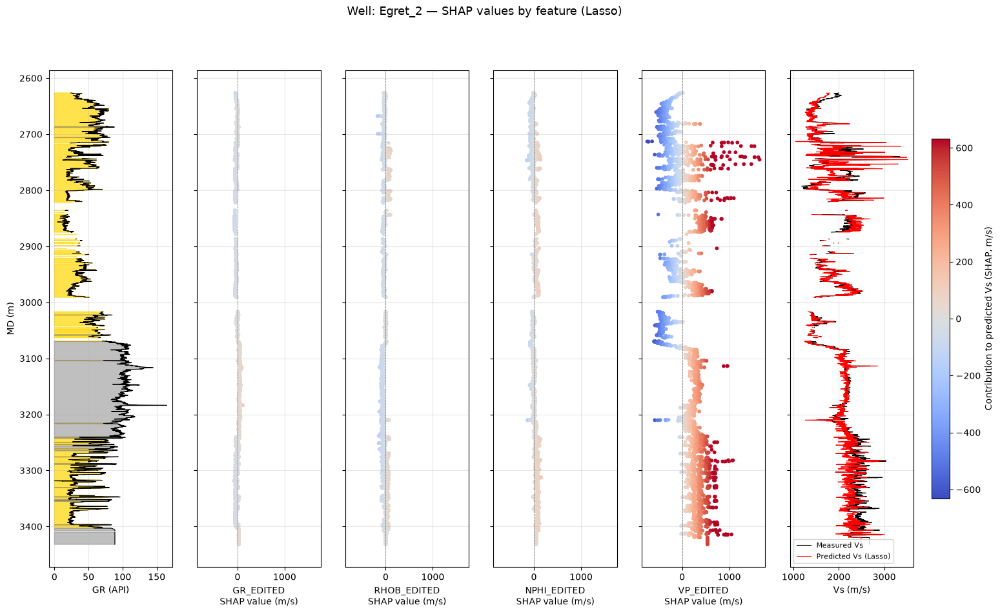

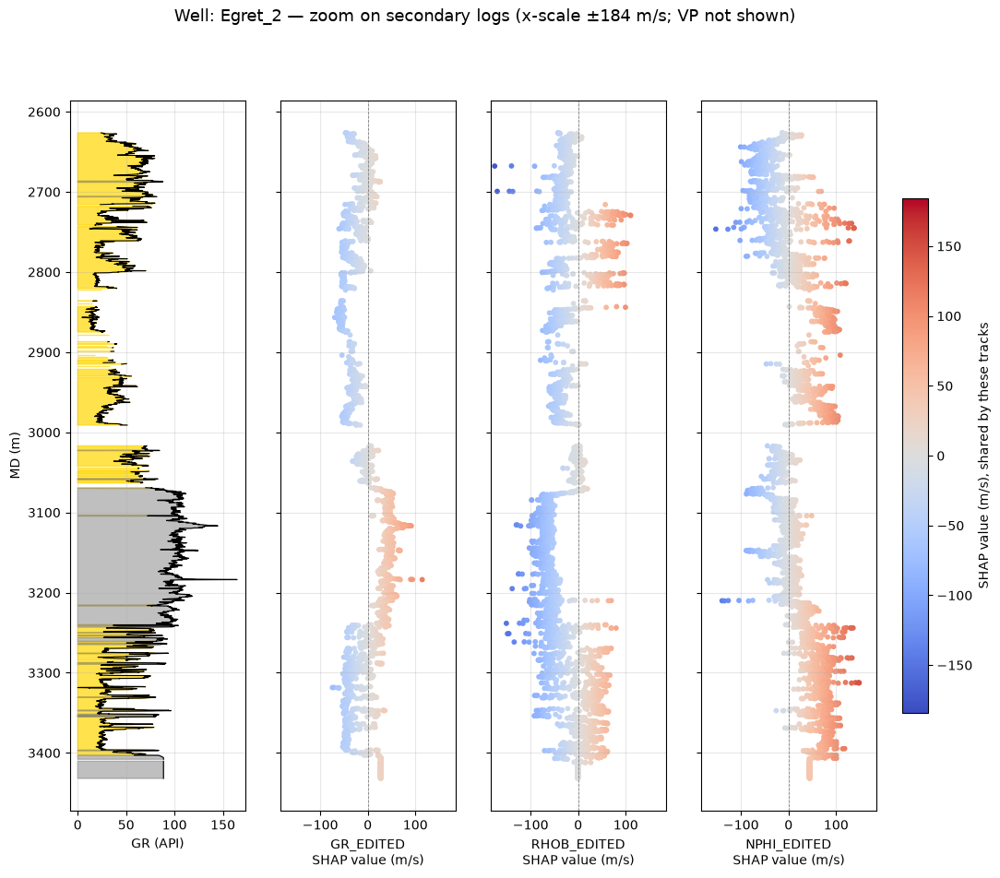

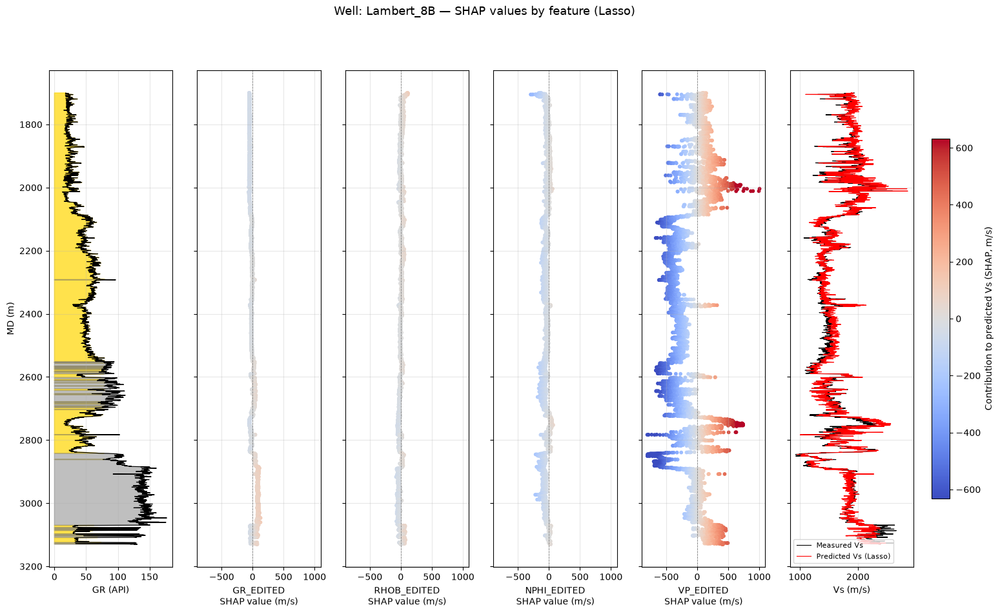

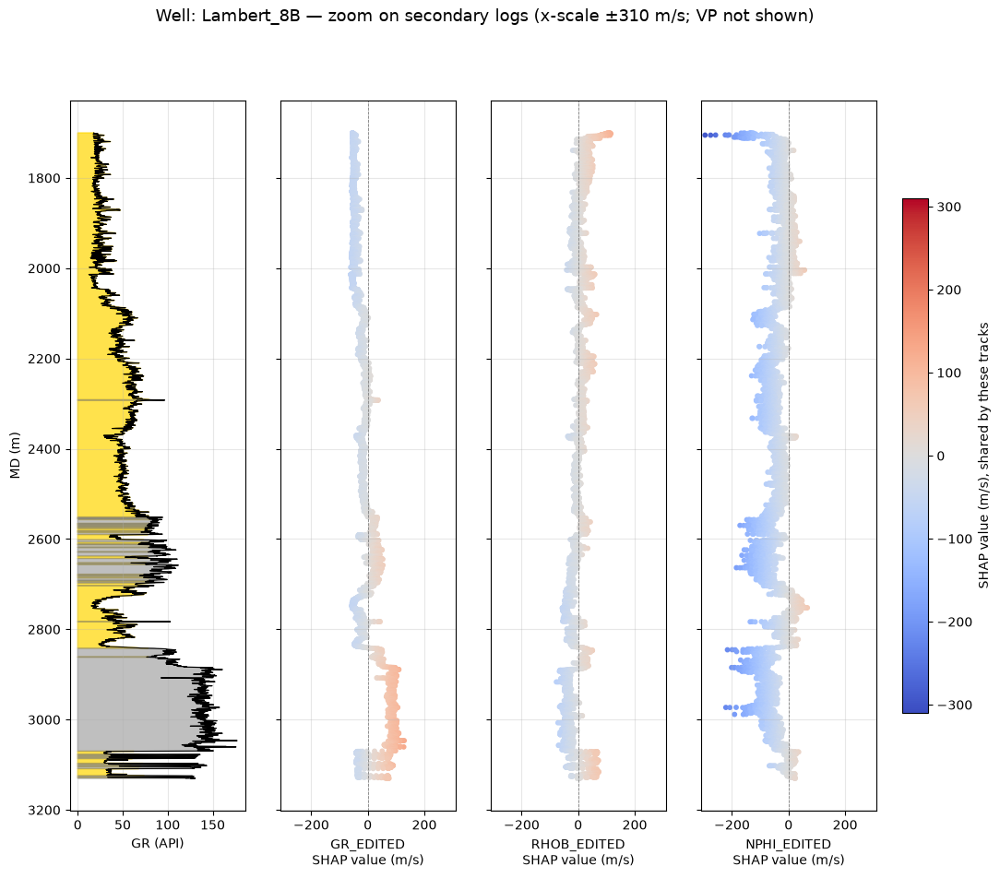

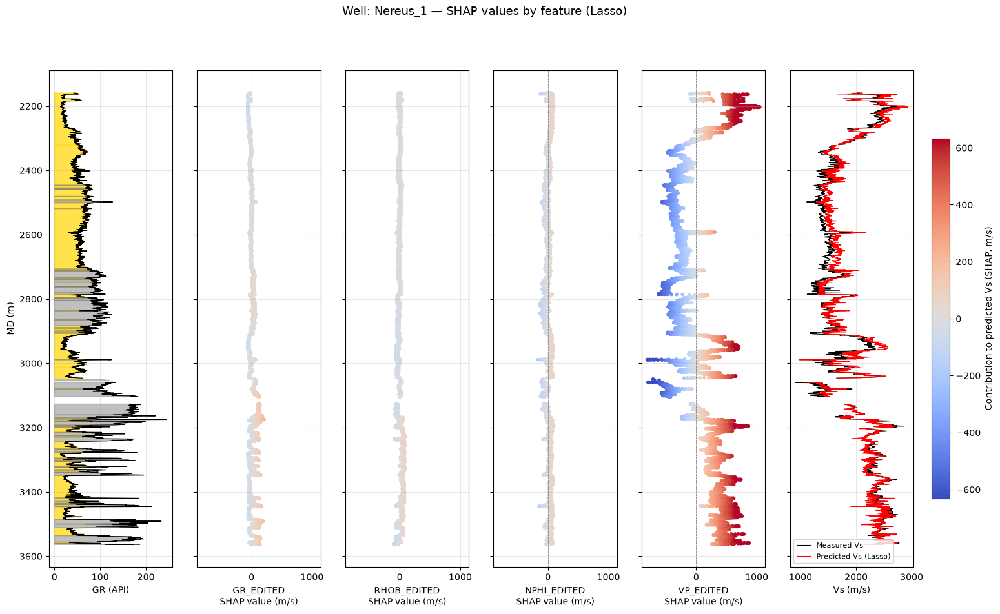

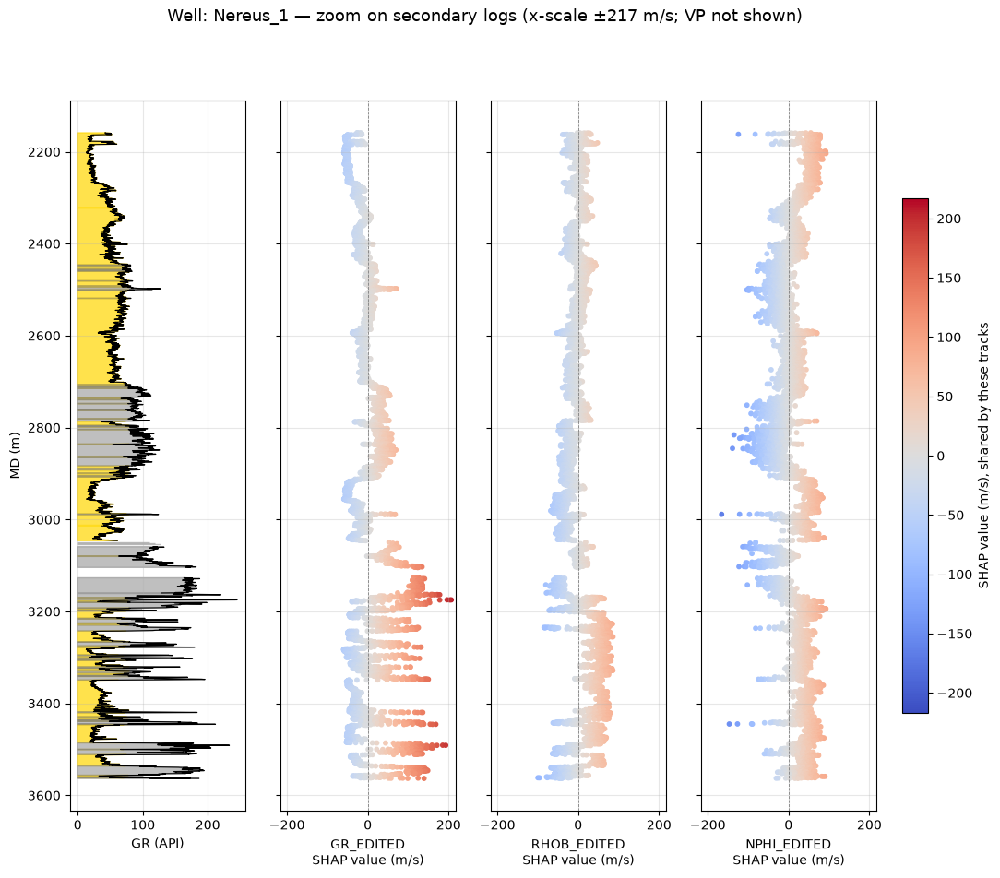

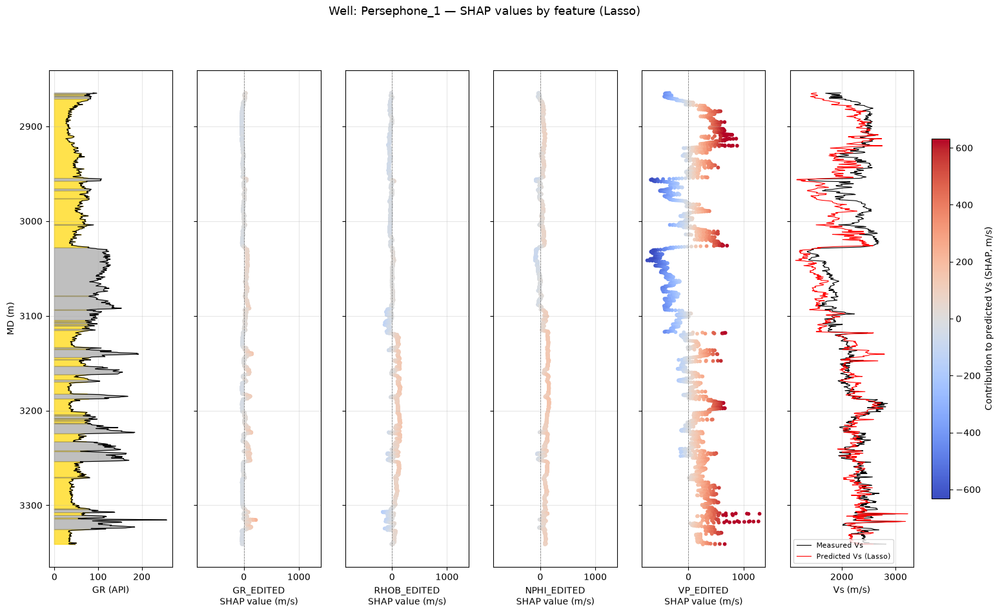

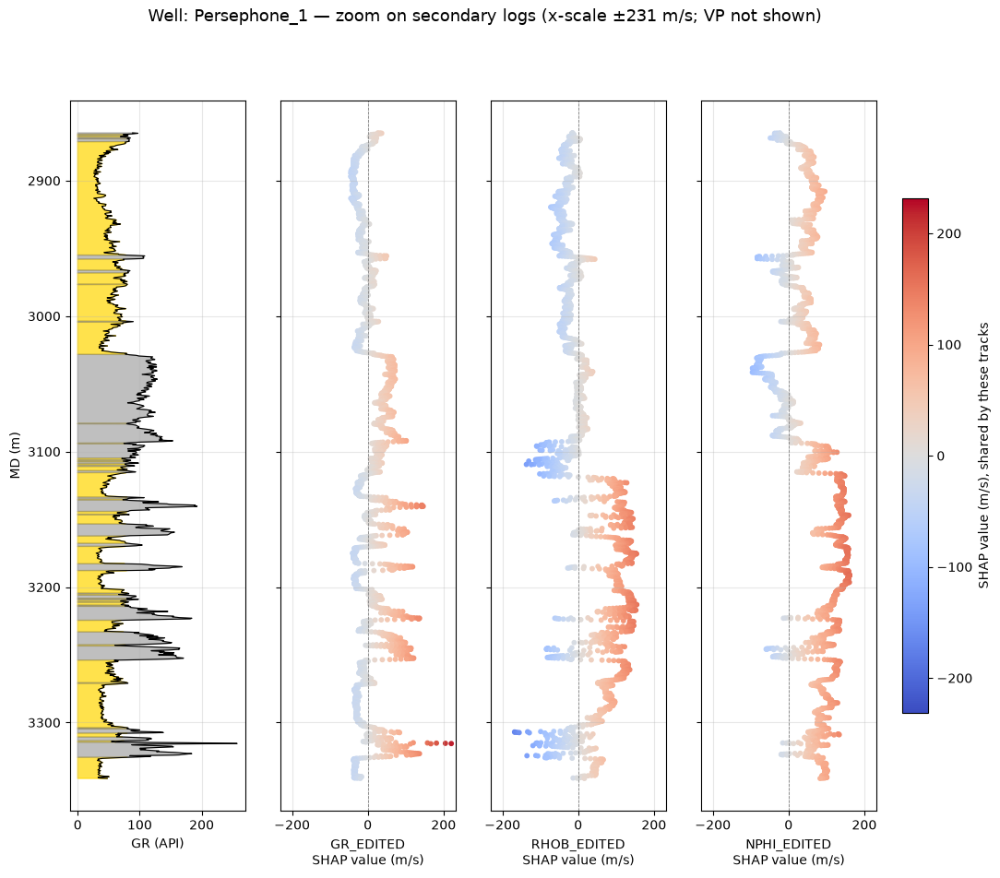

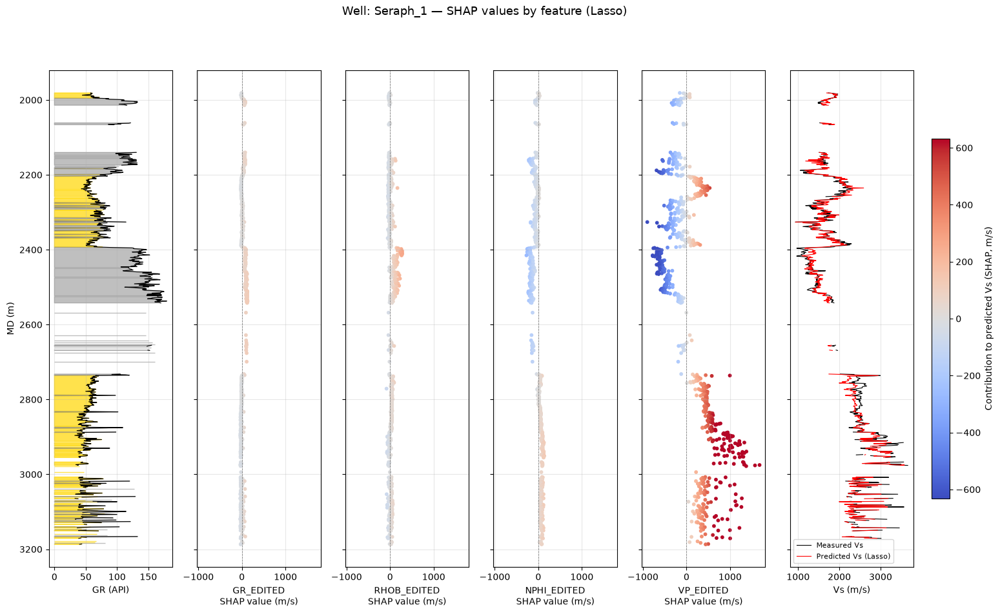

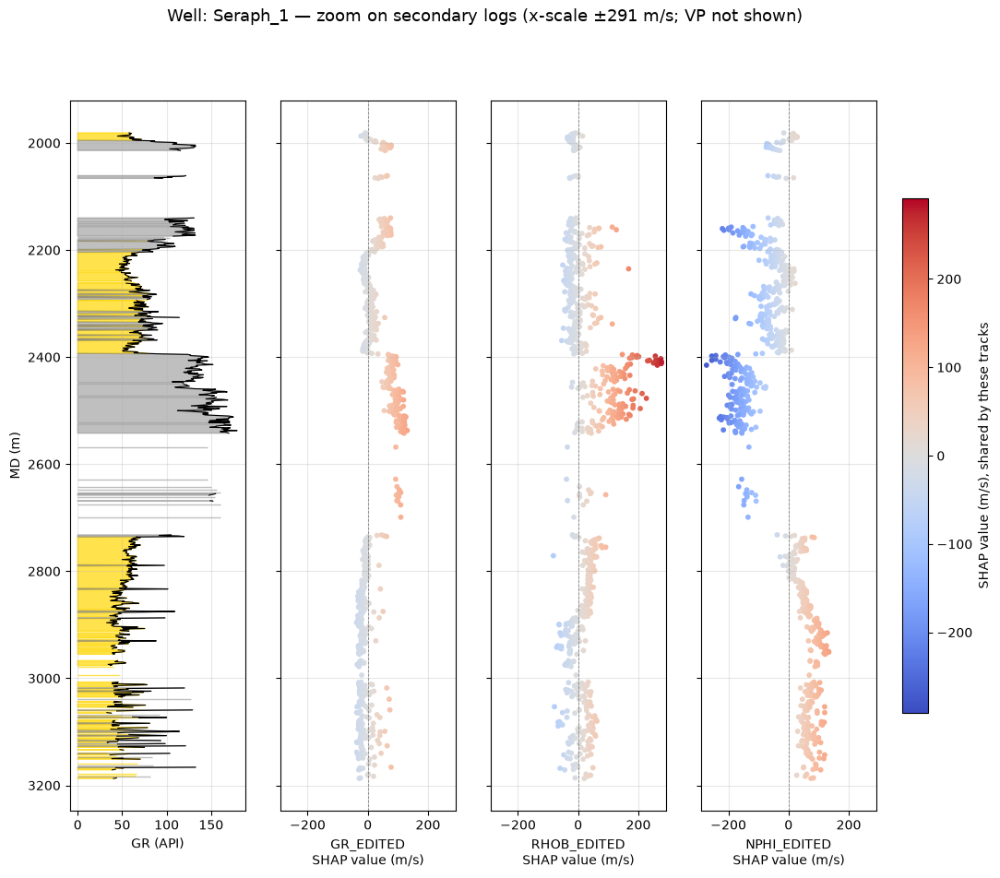

In [28]:
# ===========================================================================
# SHAP depth tracks (Lasso) - raw SHAP values in m/s, no per-feature normalisation
# ===========================================================================
# SHAP values are all in m/s of Vs, so they are directly comparable between
# features. Within each figure, every SHAP track shares one x-axis and one colour
# scale, so the relative size of each feature's contribution is shown honestly.
#
# Table     : mean |SHAP| per feature per well (m/s and % share)
# Figure 1  : GR | SHAP for GR, RHOB, NPHI, VP | measured vs predicted Vs
# Figure 2  : (optional) zoom on the secondary logs GR, RHOB, NPHI on their own
#             shared scale - shows WHERE they adjust Vs (VP not shown)

SHOW_ZOOM = True

# RESD_LOG is left out of the figures: Lasso set its coefficient to 0, so its SHAP
# value is exactly 0 everywhere (it still appears in the table as 0).
plot_features = [f for f in features_reg if f != 'RESD_LOG']
plot_idx = [features_reg.index(f) for f in plot_features]
minor_features = [f for f in plot_features if f != 'VP_EDITED']
minor_idx = [plot_features.index(f) for f in minor_features]   # positions within plot_features

shap_plot = shap_values[:, plot_idx]
well_names = measured_df['Well Name'].str.replace('_with_formation', '').values

# ---------------------------------------------------------------------------
# 1. How big is each feature's contribution?  mean |SHAP| (m/s) and % share
# ---------------------------------------------------------------------------
abs_shap = pd.DataFrame(np.abs(shap_values), columns=features_reg)
imp_ms = abs_shap.assign(Well=well_names).groupby('Well').mean()
imp_ms.loc['All wells'] = abs_shap.mean()
imp_pct = imp_ms.div(imp_ms.sum(axis=1), axis=0) * 100

print("Mean |SHAP| per feature (m/s of Vs):")
display(imp_ms.round(0))
print("Share of total contribution (%):")
display(imp_pct.round(1))
imp_ms.round(1).to_csv(FIGURES_DIR / "shap_mean_abs_by_well.csv")

# ---------------------------------------------------------------------------
# 2. Shared settings and helpers
# ---------------------------------------------------------------------------
# Colour scale for Figure 1, shared by all features and all wells,
# clipped at the 99th percentile of |SHAP| so a few extreme points don't dominate
c_max = np.percentile(np.abs(shap_plot), 99)

# Predicted Vs from the same model the SHAP values explain (in-sample, not LOWO)
vs_pred_all = model_full.predict(X_full)

# GR sand/shale cutoff for the reference track
gr_min = data_df['GR_EDITED'].quantile(0.05)   # ~clean sand baseline
gr_max = data_df['GR_EDITED'].quantile(0.95)   # ~shale baseline
cutoff = (gr_min + gr_max) / 2
print(f"GR min (5th pct): {gr_min:.1f}, GR max (95th pct): {gr_max:.1f}, cutoff: {cutoff:.1f}")


def break_gaps(depth, *curves, max_step=1.0):
    """Insert NaN where depth jumps by more than max_step (m), so lines break
    at missing-data gaps instead of drawing a straight line across them."""
    d = np.asarray(depth, dtype=float)
    gap_pos = np.where(np.diff(d) > max_step)[0] + 1
    out = [np.insert(d, gap_pos, np.nan)]
    for c in curves:
        out.append(np.insert(np.asarray(c, dtype=float), gap_pos, np.nan))
    return out


def padded(lo, hi, frac=0.05):
    pad = frac * (hi - lo) if hi > lo else 1.0
    return lo - pad, hi + pad


def draw_gr_track(ax, depth, gr):
    d, g = break_gaps(depth, gr)
    ax.fill_betweenx(d, 0, g, where=(g <= cutoff), color='gold', alpha=0.7, interpolate=True)
    ax.fill_betweenx(d, 0, g, where=(g > cutoff), color='gray', alpha=0.5, interpolate=True)
    ax.plot(g, d, color='black', lw=0.8)
    ax.set_xlabel('GR (API)')
    ax.set_ylabel('MD (m)')
    ax.grid(alpha=0.3)
    ax.invert_yaxis()


def draw_shap_track(ax, values, depth, feat, x_lim, c_lim):
    sc = ax.scatter(values, depth, c=values, cmap='coolwarm', vmin=-c_lim, vmax=c_lim, s=10)
    ax.axvline(0, color='gray', lw=0.6, ls='--')
    ax.set_xlim(*x_lim)
    ax.set_xlabel(f'{feat}\nSHAP value (m/s)')
    ax.grid(alpha=0.3)
    return sc


# ---------------------------------------------------------------------------
# 3. Figures, one set per measured well
# ---------------------------------------------------------------------------
for well in measured_wells:
    name = well.replace('_with_formation', '')
    well_mask = (measured_df['Well Name'] == well).values
    well_shap = shap_plot[well_mask]
    depth = measured_df.loc[well_mask, 'MD'].values
    gr = measured_df.loc[well_mask, 'GR_EDITED'].values
    vs_meas = measured_df.loc[well_mask, 'VS_EDITED_V2'].values
    vs_pred = vs_pred_all[well_mask]

    # ---- Figure 1: all SHAP tracks on one shared x-axis (per well) ----------
    x_lim = padded(well_shap.min(), well_shap.max())
    n_tracks = len(plot_features) + 2          # GR + SHAP tracks + Vs
    fig, axes = plt.subplots(nrows=1, ncols=n_tracks, figsize=(3 * n_tracks, 10), sharey=True)

    draw_gr_track(axes[0], depth, gr)
    for j, feat in enumerate(plot_features):
        sc = draw_shap_track(axes[j + 1], well_shap[:, j], depth, feat, x_lim, c_max)

    d_vs, vs_m_g, vs_p_g = break_gaps(depth, vs_meas, vs_pred)
    ax_vs = axes[-1]
    ax_vs.plot(vs_m_g, d_vs, color='black', lw=0.8, label='Measured Vs')
    ax_vs.plot(vs_p_g, d_vs, color='red', lw=0.8, label='Predicted Vs (Lasso)')
    ax_vs.set_xlabel('Vs (m/s)')
    ax_vs.legend(loc='lower left', fontsize=8)
    ax_vs.grid(alpha=0.3)

    cbar = fig.colorbar(sc, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label('Contribution to predicted Vs (SHAP, m/s)')
    fig.suptitle(f'Well: {name} \u2014 SHAP values by feature (Lasso)', fontsize=13)
    plt.savefig(FIGURES_DIR / f"shap_track_{name}.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ---- Figure 2: zoom on the secondary logs (own shared scale) ------------
    if SHOW_ZOOM:
        minor_shap = well_shap[:, minor_idx]
        z = np.abs(minor_shap).max() * 1.05     # shared by the 3 zoom tracks
        n_z = len(minor_features) + 1           # GR + zoom tracks
        fig, axes = plt.subplots(nrows=1, ncols=n_z, figsize=(3 * n_z, 10), sharey=True)

        draw_gr_track(axes[0], depth, gr)
        for j, feat in enumerate(minor_features):
            sc = draw_shap_track(axes[j + 1], minor_shap[:, j], depth, feat, (-z, z), z)

        cbar = fig.colorbar(sc, ax=axes, fraction=0.03, pad=0.03)
        cbar.set_label('SHAP value (m/s), shared by these tracks')
        fig.suptitle(f'Well: {name} \u2014 zoom on secondary logs (x-scale \u00b1{z:.0f} m/s; VP not shown)',
                     fontsize=13)
        plt.savefig(FIGURES_DIR / f"shap_track_zoom_{name}.png", dpi=300, bbox_inches='tight')
        plt.show()

In [29]:
w = data_df[data_df['Well Name'].str.contains('Egret_2')].sort_values('MD').reset_index(drop=True)

# 1. Depth jumps (normal step is ~0.15 m; anything > 1 m means missing rows)
step = w['MD'].diff()
print("Normal depth step:", round(step.median(), 3), "m")
print("\nDepth jumps > 1 m:")
print(w.loc[step > 1, ['MD']].assign(jump_m=step[step > 1].round(1),
                                     previous_MD=w['MD'].shift()[step > 1]))

# 2. Where are the extreme VP SHAP points (> 1500 m/s)?
eg_mask = (measured_df['Well Name'].str.contains('Egret_2')).values
eg_vp_shap = shap_values[eg_mask, features_reg.index('VP_EDITED')]
eg_md = measured_df.loc[eg_mask, 'MD'].values
eg_vp = measured_df.loc[eg_mask, 'VP_EDITED'].values
print("\nRows with VP SHAP > 1500:", (eg_vp_shap > 1500).sum())
print("Depth range:", eg_md[eg_vp_shap > 1500].min().round(1), "-", eg_md[eg_vp_shap > 1500].max().round(1), "m")
print("VP values there:", eg_vp[eg_vp_shap > 1500].min().round(0), "-", eg_vp[eg_vp_shap > 1500].max().round(0), "m/s")

Normal depth step: 0.152 m

Depth jumps > 1 m:
             MD  jump_m  previous_MD
588   2717.7492     2.0    2715.7680
739   2743.2000     1.7    2741.5236
1242  2822.4480     2.0    2820.4668
1243  2835.8592    13.4    2822.4480
1247  2839.2120     2.9    2836.3164
1248  2843.1744     4.0    2839.2120
1453  2878.5312     3.7    2874.8736
1454  2886.9132     8.4    2878.5312
1457  2889.3516     2.1    2887.2180
1462  2892.0948     2.0    2890.1136
1463  2894.2284     2.1    2892.0948
1465  2898.9528     4.6    2894.3808
1467  2903.6772     4.6    2899.1052
1468  2905.8108     2.1    2903.6772
1469  2907.1824     1.4    2905.8108
1470  2909.4684     2.3    2907.1824
1476  2912.5164     1.7    2910.8400
1479  2914.3452     1.2    2913.1260
1483  2917.0884     2.1    2914.9548
1484  2921.3556     4.3    2917.0884
1541  2931.4140     1.5    2929.8900
1933  3016.9104    25.9    2991.0024
2099  3044.6472     2.4    3042.2088
2102  3046.1712     1.2    3044.9520
2103  3047.5428     1.4    3

In [30]:
iv = w[(w['MD'] >= 2700) & (w['MD'] <= 2780)].copy()

# 1. Linear interpolation check: in a straight-line segment the 2nd difference is ~0
for col in ['VP_EDITED', 'VS_EDITED_V2', 'RHOB_EDITED', 'GR_EDITED']:
    d2 = iv[col].diff().diff().abs()
    straight = (d2 < 1e-6)
    runs = (straight != straight.shift()).cumsum()
    longest = straight.groupby(runs).sum().max()
    print(f"{col}: longest straight-line run = {int(longest)} rows (~{longest*0.152:.1f} m)")

# 2. The 10 spike rows
spike_md = eg_md[eg_vp_shap > 1500]
cols = ['MD', 'Formation', 'VP_EDITED', 'VS_EDITED_V2', 'RHOB_EDITED', 'CALCITE_COMBINER', 'PHIT_QEPP']
print(w[w['MD'].round(3).isin(spike_md.round(3))][cols].round(3).to_string(index=False))

VP_EDITED: longest straight-line run = 0 rows (~0.0 m)
VS_EDITED_V2: longest straight-line run = 0 rows (~0.0 m)
RHOB_EDITED: longest straight-line run = 0 rows (~0.0 m)
GR_EDITED: longest straight-line run = 0 rows (~0.0 m)
      MD   Formation  VP_EDITED  VS_EDITED_V2  RHOB_EDITED  CALCITE_COMBINER  PHIT_QEPP
2721.407 Withnell Fm   5757.820      1857.190        2.600             0.000      0.081
2740.914 Withnell Fm   5759.920      3383.949        2.455             0.752      0.141
2741.066 Withnell Fm   5763.533      2842.411        2.368             0.692      0.184
2741.219 Withnell Fm   5877.494      2715.733        2.317             0.659      0.204
2745.334 Withnell Fm   5911.673      3107.970        2.690             0.936      0.009


In [31]:
WELL = 'Persephone_1'   # well to display

w = data_df[data_df['Well Name'].str.contains(WELL)].sort_values('MD').copy()
w['VpVs'] = w['VP_EDITED'] / w['VS_EDITED_V2']
w['bad_vp'] = (w['VP_EDITED'] > 6600) | (w['VpVs'] > 2.5)

print(f"=== {WELL} ===")
print(f"Rows: {len(w)},  bad VP rows: {w['bad_vp'].sum()} ({100*w['bad_vp'].mean():.2f}%)")
print(f"Vp/Vs: 1st pct = {w['VpVs'].quantile(0.01):.2f}, median = {w['VpVs'].median():.2f}, 99th pct = {w['VpVs'].quantile(0.99):.2f}")

bad = w[w['bad_vp']]
if len(bad):
    print("\nBad rows by formation:")
    print(bad['Formation'].value_counts())
    print("\nBad rows:")
    print(bad[['MD', 'Formation', 'VP_EDITED', 'VS_EDITED_V2', 'VpVs', 'CALCITE_COMBINER', 'PHIT_QEPP']]
          .round(2).to_string(index=False))

=== Persephone_1 ===
Rows: 3128,  bad VP rows: 0 (0.00%)
Vp/Vs: 1st pct = 1.48, median = 1.68, 99th pct = 1.98


In [32]:
m = data_df[data_df['Well Name'].str.contains('Egret_2|Lambert_8B|Nereus_1|Persephone_1|Seraph_1')].copy()
m['VpVs'] = m['VP_EDITED'] / m['VS_EDITED_V2']
m['flag'] = (m['VP_EDITED'] > 6600) | (m['VpVs'] > 2.5)

f = m[m['flag']]
print(f.groupby(['Well Name', 'Formation'])[['GR_EDITED', 'VCL_GEO_QEPP', 'CALI_EDITED', 'VpVs']]
       .agg(['min', 'max']).round(2).to_string())

                                               GR_EDITED         VCL_GEO_QEPP       CALI_EDITED         VpVs      
                                                     min     max          min   max         min    max   min   max
Well Name                 Formation                                                                               
Egret_2_with_formation    Withnell Fm              34.83   67.69         0.20  0.44       13.06  14.98  2.53  3.43
Lambert_8B_with_formation Haycock/Windalia Fms     83.48   99.97         0.39  0.48       12.29  12.29  2.52  2.65
                          Muderong Shale           94.68  109.75         0.46  0.56       12.00  12.26  2.50  2.69
Nereus_1_with_formation   Muderong Shale          115.44  132.83         0.72  0.79        8.32   8.38  2.58  2.78
                          Walcott/Wilcox Fms      110.18  127.08         0.76  0.79        8.49   8.54  2.51  2.52
                          Windalia Radiolarite    114.16  115.73         0.75  0

## 8b. Vp–Vs relationship (data QC + Lasso fit)

A standard rock-physics check: actual Vp vs actual Vs across the 5 measured wells, with the final Lasso model's fitted Vs overlaid, plus Castagna's mudrock line (Vs = 0.804·Vp − 856 m/s) as a reference trend for clean, water-saturated siliciclastics -- not a fit to this data, just a sanity-check baseline. This also sets up the Vp/Vs ratio needed for Poisson's ratio in the next phase.

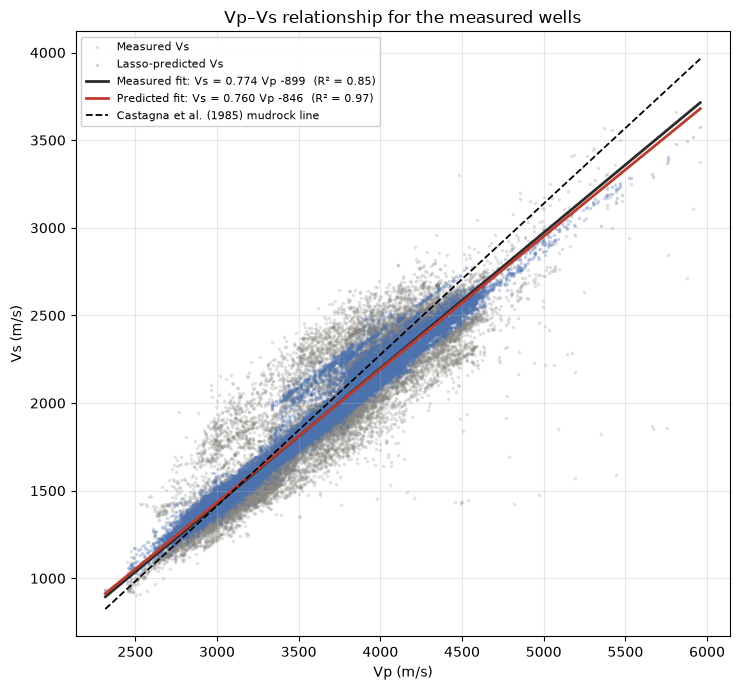

Measured : Vs = 0.774 Vp -899, R2 = 0.851
Predicted: Vs = 0.760 Vp -846, R2 = 0.970


In [33]:
vs_pred_full = model_full.predict(X_full)
vp_full = measured_df['VP_EDITED'].values
vs_actual_full = measured_df[target_reg].values

def linfit(x, y):
    a, b = np.polyfit(x, y, 1)
    r2 = np.corrcoef(x, y)[0, 1] ** 2
    return a, b, r2

a_m, b_m, r2_m = linfit(vp_full, vs_actual_full)   # fit to measured Vs
a_p, b_p, r2_p = linfit(vp_full, vs_pred_full)     # fit to Lasso-predicted Vs
vp_range = np.linspace(vp_full.min(), vp_full.max(), 100)
castagna_vs = 0.862 * vp_range - 1172              # Castagna et al. (1985) mudrock line, Vs = 0.862 Vp - 1.172 km/s

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(vp_full, vs_actual_full, s=6, alpha=0.25, color='#898781', linewidths=0, label='Measured Vs', rasterized=True)
ax.scatter(vp_full, vs_pred_full, s=6, alpha=0.30, color='#4C72B0', linewidths=0, label='Lasso-predicted Vs', rasterized=True)
ax.plot(vp_range, a_m * vp_range + b_m, color='#2b2b2b', lw=2,
        label=f'Measured fit: Vs = {a_m:.3f} Vp {b_m:+.0f}  (R² = {r2_m:.2f})')
ax.plot(vp_range, a_p * vp_range + b_p, color='#c0392b', lw=2,
        label=f'Predicted fit: Vs = {a_p:.3f} Vp {b_p:+.0f}  (R² = {r2_p:.2f})')
ax.plot(vp_range, castagna_vs, 'k--', lw=1.3, label='Castagna et al. (1985) mudrock line')
ax.set_xlabel('Vp (m/s)')
ax.set_ylabel('Vs (m/s)')
ax.set_title('Vp–Vs relationship for the measured wells')
ax.legend(fontsize=8, loc='upper left', framealpha=0.95)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vp_vs_relationship_fits.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"Measured : Vs = {a_m:.3f} Vp {b_m:+.0f}, R2 = {r2_m:.3f}")
print(f"Predicted: Vs = {a_p:.3f} Vp {b_p:+.0f}, R2 = {r2_p:.3f}")

## 9. Outlier check (EDA)

Note: resistivity is now fed into the models as `RESD_LOG` (log10 of RESD_EDITED), so the raw-scale skew that used to flag much of its normal long tail as "outliers" no longer applies the same way — this check reflects the log-transformed feature actually used by the models, not the raw ohm-m values.

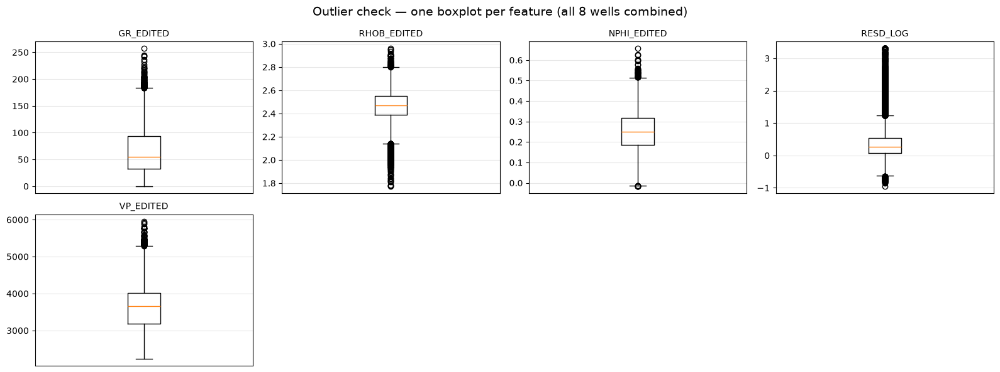

In [34]:
ncols = 4
nrows = (len(features_reg) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = axes.flatten()

for ax, feature in zip(axes, features_reg):
    ax.boxplot(data_df[feature].dropna())
    ax.set_title(feature, fontsize=10)
    ax.set_xticks([])
    ax.grid(alpha=0.3)

for ax in axes[len(features_reg):]:
    ax.remove()

fig.suptitle('Outlier check — one boxplot per feature (all 8 wells combined)', fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "outlier_check_boxplots.png", dpi=300, bbox_inches='tight')
plt.show()


In [35]:
outlier_counts = {}

for feature in features_reg:
    q1 = data_df[feature].quantile(0.25)
    q3 = data_df[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_counts[feature] = ((data_df[feature] < lower) | (data_df[feature] > upper)).sum()

outlier_df = pd.DataFrame.from_dict(outlier_counts, orient='index', columns=['Outlier Count'])
outlier_df['% of samples'] = (outlier_df['Outlier Count'] / len(data_df) * 100).round(2)
outlier_df.sort_values('Outlier Count', ascending=False)


,Outlier Count,% of samples
RESD_LOG,1907,3.92
RHOB_EDITED,1027,2.11
GR_EDITED,118,0.24
VP_EDITED,93,0.19
NPHI_EDITED,44,0.09


# Part 2 — Train on Measured Wells, Predict Modelled-Only Wells

Different from LOWO: here we train **one final model** using all 5 measured-Vs wells at once (no rotation, since none of them are being tested), then use that single model to predict Vs for the 3 wells that never had a real measurement (Angel_1, Angel_3, Wanaea_11A). This is a closer rehearsal of the real deployment scenario (predicting Vs where it was never measured) than LOWO is.

Comparison columns are labelled "vs SLB estimate" rather than R2/RMSE/MAE on purpose — `VS_EDITED_V2` for these 3 wells is SLB's own GC-based estimate, not a real measurement, so this is an agreement check between two independent estimates, not a validated accuracy score.

## 10. Build training/prediction sets

In [36]:
train_df = data_df[data_df['Well Name'].isin(measured_wells)]
predict_df = data_df[data_df['Well Name'].isin(modelled_wells)].copy()

print("Training samples (5 measured wells):", len(train_df))
print("Samples to predict (3 modelled-only wells):", len(predict_df))

Training samples (5 measured wells): 26749
Samples to predict (3 modelled-only wells): 21949


## 11. Linear Regression — train on measured, predict modelled-only

In [37]:
model_final_lr = LinearRegression()
model_final_lr.fit(train_df[features_reg], train_df[target_reg])

predict_df['VS_PRED'] = model_final_lr.predict(predict_df[features_reg])


In [38]:
results = []

for well in modelled_wells:
    well_df = predict_df[predict_df['Well Name'] == well]

    results.append({
        'Well': well,
        'R2 vs SLB estimate': r2_score(well_df[target_reg], well_df['VS_PRED']),
        'RMSE vs SLB estimate': np.sqrt(mean_squared_error(well_df[target_reg], well_df['VS_PRED'])),
        'MAE vs SLB estimate': mean_absolute_error(well_df[target_reg], well_df['VS_PRED'])
    })

results_vs_slb_vs_pred = pd.DataFrame(results)
results_vs_slb_vs_pred


,Well,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
0,Angel_1_with_formation,0.802147,195.637171,159.490125
1,Angel_3_with_formation,0.838831,185.253197,148.917379
2,Wanaea_11A_with_formation,0.845030,108.349038,77.347885


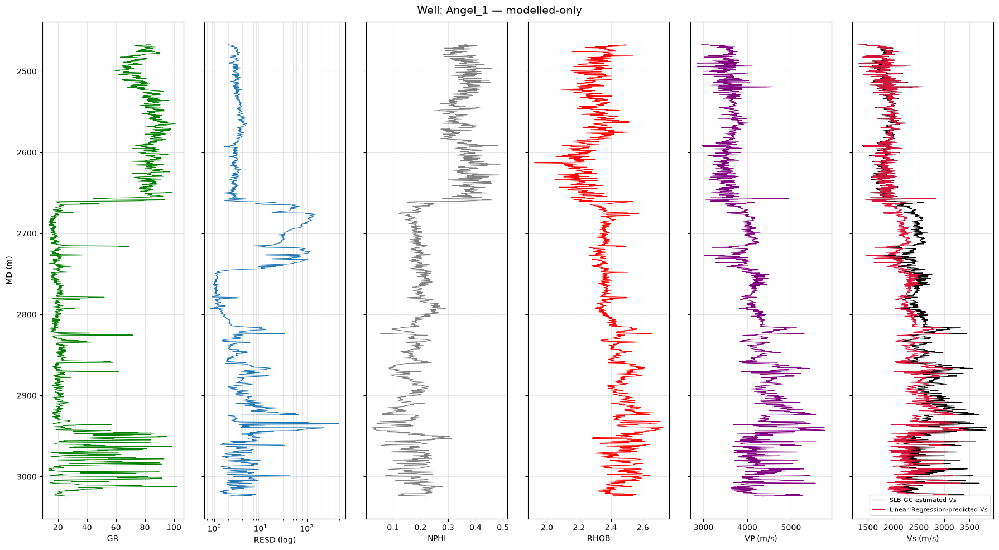

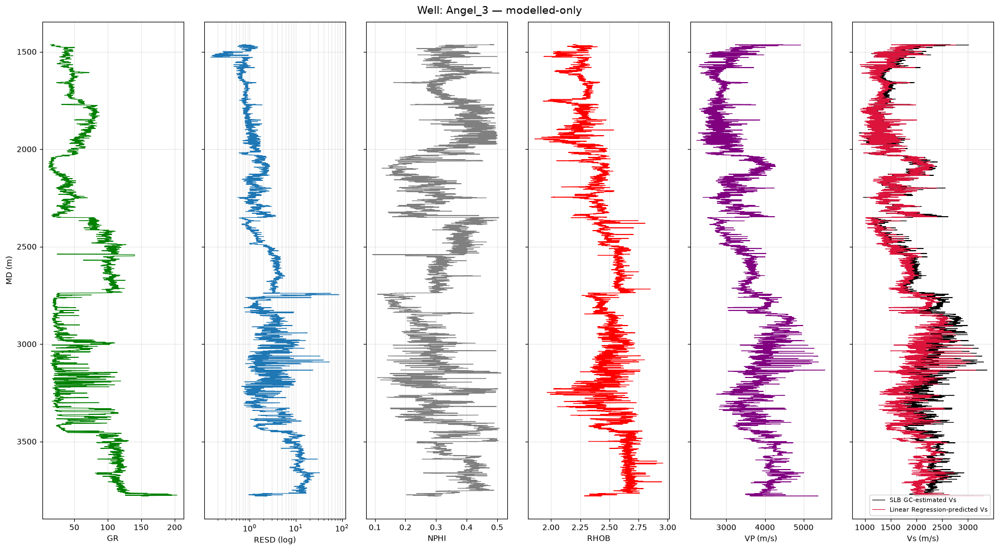

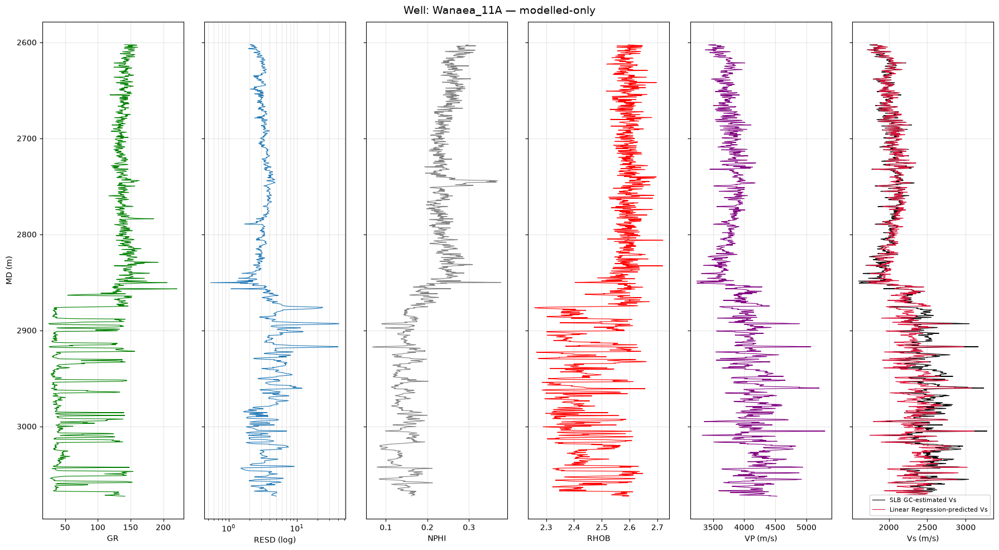

In [39]:
for well in modelled_wells:

    well_df = predict_df[predict_df['Well Name'] == well]
    depth = well_df['MD']

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(18, 10), sharey=True)

    axes[0].plot(well_df['GR_EDITED'], depth, color='green', lw=0.8)
    axes[0].set_xlabel('GR')
    axes[0].grid(alpha=0.3)

    axes[1].plot(well_df['RESD_EDITED'], depth, color='tab:blue', lw=0.8)
    axes[1].set_xscale('log')
    axes[1].set_xlabel('RESD (log)')
    axes[1].grid(alpha=0.3, which='both')

    axes[2].plot(well_df['NPHI_EDITED'], depth, color='gray', lw=0.8)
    axes[2].set_xlabel('NPHI')
    axes[2].grid(alpha=0.3)

    axes[3].plot(well_df['RHOB_EDITED'], depth, color='red', lw=0.8)
    axes[3].set_xlabel('RHOB')
    axes[3].grid(alpha=0.3)

    axes[4].plot(well_df['VP_EDITED'], depth, color='purple', lw=0.8)
    axes[4].set_xlabel('VP (m/s)')
    axes[4].grid(alpha=0.3)

    axes[5].plot(well_df[target_reg], depth, color='black', lw=0.8, label='SLB GC-estimated Vs')
    axes[5].plot(well_df['VS_PRED'], depth, color='crimson', lw=0.8, label='Linear Regression-predicted Vs')
    axes[5].set_xlabel('Vs (m/s)')
    axes[5].legend(fontsize=8, loc='lower right')
    axes[5].grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel('MD (m)')
    fig.suptitle(f'Well: {well.replace("_with_formation", "")} — modelled-only', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"linear_part2_multitrack_{well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

## 12. Ridge Regression — train on measured, predict modelled-only

In [40]:
model_final_ridge = Ridge(alpha=1.0)
model_final_ridge.fit(train_df[features_reg], train_df[target_reg])

predict_df['VS_PRED_RIDGE'] = model_final_ridge.predict(predict_df[features_reg])


In [41]:
results = []

for well in modelled_wells:
    well_df = predict_df[predict_df['Well Name'] == well]

    results.append({
        'Well': well,
        'R2 vs SLB estimate': r2_score(well_df[target_reg], well_df['VS_PRED_RIDGE']),
        'RMSE vs SLB estimate': np.sqrt(mean_squared_error(well_df[target_reg], well_df['VS_PRED_RIDGE'])),
        'MAE vs SLB estimate': mean_absolute_error(well_df[target_reg], well_df['VS_PRED_RIDGE'])
    })

results_vs_slb_vs_pred_ridge = pd.DataFrame(results)
results_vs_slb_vs_pred_ridge


,Well,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
0,Angel_1_with_formation,0.803105,195.163262,159.265675
1,Angel_3_with_formation,0.840659,184.199399,148.033644
2,Wanaea_11A_with_formation,0.844884,108.400279,77.386867


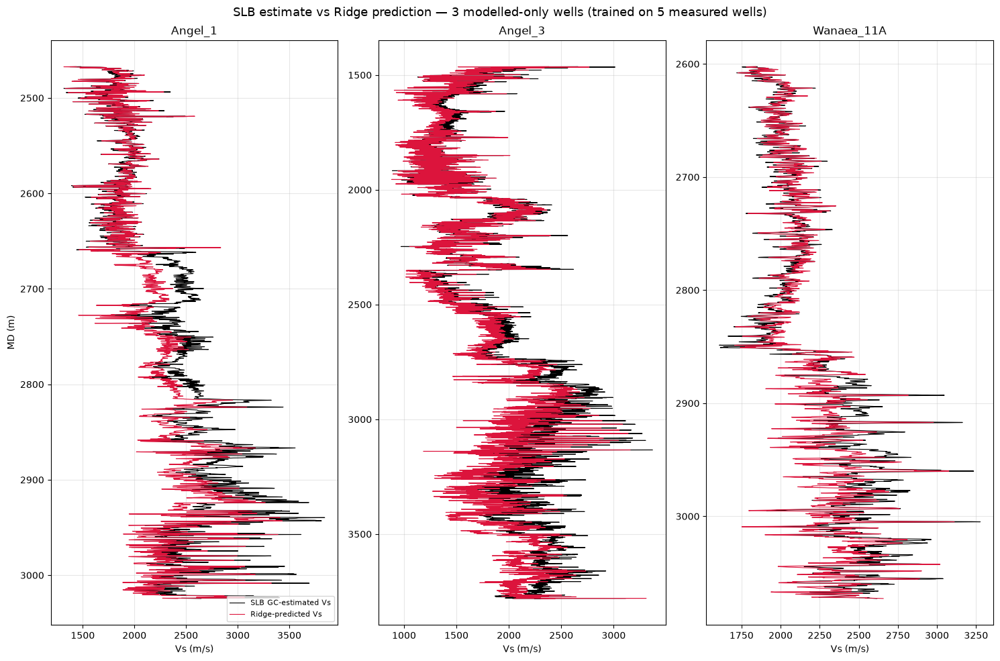

In [42]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

for ax, well in zip(axes, modelled_wells):
    well_df = predict_df[predict_df['Well Name'] == well]

    ax.plot(well_df[target_reg], well_df['MD'], color='black', lw=0.8, label='SLB GC-estimated Vs')
    ax.plot(well_df['VS_PRED_RIDGE'], well_df['MD'], color='crimson', lw=0.8, label='Ridge-predicted Vs')
    ax.invert_yaxis()
    ax.set_xlabel('Vs (m/s)')
    ax.set_title(well.replace('_with_formation', ''))
    ax.grid(alpha=0.3)

axes[0].set_ylabel('MD (m)')
axes[0].legend(fontsize=8, loc='lower right')

fig.suptitle('SLB estimate vs Ridge prediction — 3 modelled-only wells (trained on 5 measured wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ridge_part2_comparison.png", dpi=300, bbox_inches='tight')
plt.show()


## 13. Lasso Regression — train on measured, predict modelled-only

In [43]:
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(train_df[features_reg])
X_predict_scaled = scaler_final.transform(predict_df[features_reg])

model_final_lasso = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)   # was: alpha=10
model_final_lasso.fit(X_train_scaled, train_df[target_reg])            

predict_df['VS_PRED_LASSO'] = model_final_lasso.predict(X_predict_scaled)

In [44]:
results = []

for well in modelled_wells:
    well_df = predict_df[predict_df['Well Name'] == well]

    results.append({
        'Well': well,
        'R2 vs SLB estimate': r2_score(well_df[target_reg], well_df['VS_PRED_LASSO']),
        'RMSE vs SLB estimate': np.sqrt(mean_squared_error(well_df[target_reg], well_df['VS_PRED_LASSO'])),
        'MAE vs SLB estimate': mean_absolute_error(well_df[target_reg], well_df['VS_PRED_LASSO'])
    })

results_vs_slb_vs_pred_lasso = pd.DataFrame(results)
results_vs_slb_vs_pred_lasso


,Well,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
0,Angel_1_with_formation,0.816088,188.618741,154.787853
1,Angel_3_with_formation,0.865600,169.170107,135.804912
2,Wanaea_11A_with_formation,0.834914,111.829699,77.350417


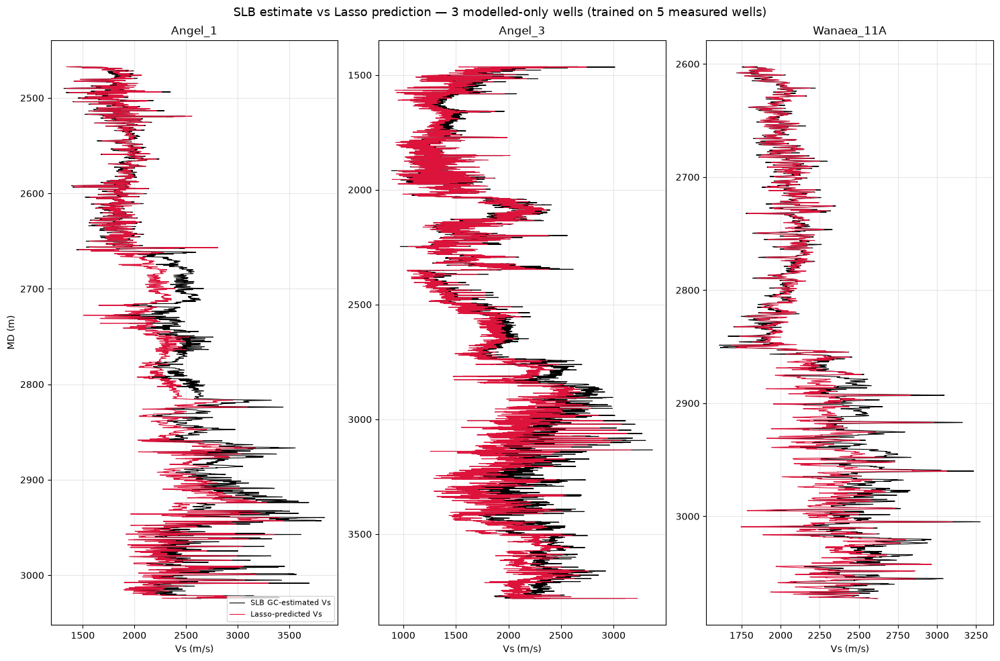

In [45]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

for ax, well in zip(axes, modelled_wells):
    well_df = predict_df[predict_df['Well Name'] == well]

    ax.plot(well_df[target_reg], well_df['MD'], color='black', lw=0.8, label='SLB GC-estimated Vs')
    ax.plot(well_df['VS_PRED_LASSO'], well_df['MD'], color='crimson', lw=0.8, label='Lasso-predicted Vs')
    ax.invert_yaxis()
    ax.set_xlabel('Vs (m/s)')
    ax.set_title(well.replace('_with_formation', ''))
    ax.grid(alpha=0.3)

axes[0].set_ylabel('MD (m)')
axes[0].legend(fontsize=8, loc='lower right')

fig.suptitle('SLB estimate vs Lasso prediction — 3 modelled-only wells (trained on 5 measured wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "lasso_part2_comparison.png", dpi=300, bbox_inches='tight')
plt.show()


## 14. Model comparison — Linear vs Ridge vs Lasso (3 modelled-only wells)

Combines the three "vs SLB estimate" tables above into one, so all three methods can be compared side by side per well.

In [46]:
results_vs_slb_vs_pred['Model'] = 'Linear Regression'
results_vs_slb_vs_pred_ridge['Model'] = 'Ridge Regression'
results_vs_slb_vs_pred_lasso['Model'] = 'Lasso Regression'

combined_part2 = pd.concat([
    results_vs_slb_vs_pred,
    results_vs_slb_vs_pred_ridge,
    results_vs_slb_vs_pred_lasso
], ignore_index=True)

combined_part2 = combined_part2[['Model', 'Well', 'R2 vs SLB estimate', 'RMSE vs SLB estimate', 'MAE vs SLB estimate']]
combined_part2['Well'] = combined_part2['Well'].str.replace('_with_formation', '', regex=False)

print("All three models, all three wells:")
display(combined_part2)

print("\nMean across the 3 wells, per model:")
display(combined_part2.groupby('Model')[['R2 vs SLB estimate', 'RMSE vs SLB estimate', 'MAE vs SLB estimate']].mean())

print("\nRMSE by well and model, side by side:")
display(combined_part2.pivot(index='Well', columns='Model', values='RMSE vs SLB estimate'))


All three models, all three wells:


,Model,Well,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
0,Linear Regression,Angel_1,0.802147,195.637171,159.490125
1,Linear Regression,Angel_3,0.838831,185.253197,148.917379
2,Linear Regression,Wanaea_11A,0.845030,108.349038,77.347885
3,Ridge Regression,Angel_1,0.803105,195.163262,159.265675
4,Ridge Regression,Angel_3,0.840659,184.199399,148.033644
5,Ridge Regression,Wanaea_11A,0.844884,108.400279,77.386867
6,Lasso Regression,Angel_1,0.816088,188.618741,154.787853
7,Lasso Regression,Angel_3,0.865600,169.170107,135.804912
8,Lasso Regression,Wanaea_11A,0.834914,111.829699,77.350417



Mean across the 3 wells, per model:


,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
Model,,,
Lasso Regression,0.838867,156.539516,122.647727
Linear Regression,0.828669,163.079802,128.585130
Ridge Regression,0.829549,162.587647,128.228728



RMSE by well and model, side by side:


Model,Lasso Regression,Linear Regression,Ridge Regression
Well,,,
Angel_1,188.618741,195.637171,195.163262
Angel_3,169.170107,185.253197,184.199399
Wanaea_11A,111.829699,108.349038,108.400279


# Part 3 — Supporting checks (data quality and Persephone_1)

Checks used for the Discussion chapter: SUMMARY_FL meaning, Egret_2 flagged interval, Persephone_1 gas effect and Toolonga Calcilutite, and the % of real, edited and modelled Vs per well (read directly from the LAS files, over each well's full logged depth). These do not change the model results above.

### Clean-sand flag (SUMMARY_FL) check

In [47]:
fl1 = data_df[data_df['SUMMARY_FL'] == 1]
print(((fl1['VCL_GEO_QEPP'] < 0.3) & (fl1['CALCITE_COMBINER'] < 0.1) & (fl1['PHIT_QEPP'] > 0.1)).mean())

0.9871737675663618


### Egret_2: caliper in the flagged intervals

In [48]:
eg = data_df_raw if 'data_df_raw' in dir() else data_df
eg = eg[eg['Well Name'].str.contains('Egret_2')].sort_values('MD')

print("Caliper, whole well: median =", round(eg['CALI_EDITED'].median(), 2), "in")
for top, base, label in [(2715, 2722, 'calcite spikes'),
                         (2745, 2746, 'calcite spikes'),
                         (2753, 2757, 'low-Vs sand'),
                         (2795, 2798, 'borderline')]:
    iv = eg[(eg['MD'] >= top) & (eg['MD'] <= base)]['CALI_EDITED']
    print(f"{top}-{base} m ({label}): min = {iv.min():.2f}, max = {iv.max():.2f} in")

Caliper, whole well: median = 13.53 in
2715-2722 m (calcite spikes): min = 14.24, max = 14.87 in
2745-2746 m (calcite spikes): min = 12.57, max = 12.73 in
2753-2757 m (low-Vs sand): min = 13.03, max = 13.36 in
2795-2798 m (borderline): min = 14.71, max = 15.09 in


### Egret_2: logs read directly from the LAS file

In [49]:
import lasio
from pathlib import Path

path = list(LAS_DIR.rglob("Egret_2_LQC.las"))[0]

las = lasio.read(path).df().reset_index()
las.columns = las.columns.str.upper()
las = las.rename(columns={las.columns[0]: 'MD'})

cols = ['MD', 'VS_ORG', 'VS_EDITED_V2', 'VP_ORG', 'VP_EDITED']
missing = [c for c in cols if c not in las.columns]
if missing:
    print("Not found:", missing)
    print("Available columns:", las.columns.tolist())
else:
    iv = las[(las['MD'] >= 2750) & (las['MD'] <= 2760)]
    print(iv[cols].round(1).to_string(index=False))

    MD  VS_ORG  VS_EDITED_V2  VP_ORG  VP_EDITED
2750.1  1702.4        1702.4  4109.8     4109.8
2750.2  1709.7        1709.7  3215.4     3215.4
2750.4  1774.1        1774.1  4110.3     4110.3
2750.5  1770.2        1770.2  4092.9     4092.9
2750.7  1775.0        1775.0  4033.3     4033.3
2750.8  1774.4        1774.4  3975.4     3975.4
2751.0  1765.8        1765.8  3997.8     3997.8
2751.1  1690.3        1690.3  4049.7     4049.7
2751.3  1666.0        1666.0  4062.5     4062.5
2751.4  1670.0        1670.0  3920.4     3920.4
2751.6  1641.7        1641.7  4068.0     4068.0
2751.7  1639.1        1639.1  4017.8     4017.8
2751.9  1647.5        1647.5  3968.7     3968.7
2752.0  1732.1        1732.1  3678.0     3678.0
2752.2  1841.3        1841.3  3684.8     3684.8
2752.3  1882.3        1882.3  3649.8     3649.8
2752.5  1886.0        1886.0  3789.7     3789.7
2752.6  1890.2        1890.2  3531.7     3531.7
2752.8  1910.8        1910.8  3573.5     3573.5
2753.0  1941.0        1941.0  3548.3    

### Persephone_1: LOWO prediction, saturation and error summaries

In [50]:
import lasio
from sklearn.pipeline import make_pipeline

# ---------------------------------------------------------------------------
# Persephone_1: LOWO prediction + saturation + error summaries
# ---------------------------------------------------------------------------
TARGET = 'VS_EDITED_V2'
ALPHA = best_alpha             # same alpha as the Lasso LOWO cell (Section 8)
others = 'Egret_2|Lambert_8B|Nereus_1|Seraph_1'

# 1. Train on the other 4 wells, predict Persephone_1
train = data_df[data_df['Well Name'].str.contains(others)]
pers = data_df[data_df['Well Name'].str.contains('Persephone_1')].sort_values('MD').copy()

model_p = make_pipeline(StandardScaler(), Lasso(alpha=ALPHA, max_iter=10000))
model_p.fit(train[features_reg], train[TARGET])
pers['VS_PRED'] = model_p.predict(pers[features_reg])
pers['RESID'] = pers[TARGET] - pers['VS_PRED']          # + = model predicts too LOW
print(f"Persephone_1 LOWO RMSE: {np.sqrt((pers['RESID']**2).mean()):.1f} m/s   rows: {len(pers)}")

# 2. Saturation curves from the Persephone_1 LAS file
las = lasio.read(list(LAS_DIR.rglob("Persephone_1_LQC.las"))[0]).df().reset_index()
las.columns = las.columns.str.upper()
las = las.rename(columns={las.columns[0]: 'MD'})
sat_cols = [c for c in ['SW_QEPP', 'UGAS_COMBINER', 'UOIL_COMBINER'] if c in las.columns]
sat = las[['MD'] + sat_cols].sort_values('MD')
pers = pd.merge_asof(pers.drop(columns=sat_cols, errors='ignore').sort_values('MD'), sat,   # avoid duplicate columns
                     on='MD', direction='nearest', tolerance=0.05)
print("Rows matched with saturation:", pers['SW_QEPP'].notna().sum(), "of", len(pers))

# 3. Saturations (same logic as estimate_sat_from_combiner.py); oil = 0 if no oil curve
sw = pers['SW_QEPP'].clip(0, 1)
ugas = pers['UGAS_COMBINER'].fillna(0)
uoil = pers['UOIL_COMBINER'].fillna(0) if 'UOIL_COMBINER' in pers.columns else 0 * ugas
hc = (ugas + uoil).replace(0, np.nan)
pers['S_W'] = sw
pers['S_GAS'] = ((1 - sw) * ugas / hc).fillna(0)
pers['S_OIL'] = ((1 - sw) * uoil / hc).fillna(0)

# 4. Fluid class (saturation only trusted in reservoir sands)
pers['Fluid'] = np.select(
    [(pers['SUMMARY_FL'] == 1) & (pers['S_GAS'] > 0.1),
     (pers['SUMMARY_FL'] == 1) & (pers['S_OIL'] > 0.1),
     (pers['SUMMARY_FL'] == 1)],
    ['gas sand', 'oil sand', 'water sand'], default='non-reservoir')

# 5. Error summaries
def summary(g):
    return pd.Series({'rows': len(g),
                      'mean resid': g['RESID'].mean(),
                      'RMSE': np.sqrt((g['RESID']**2).mean()),
                      'depth top': g['MD'].min(), 'depth base': g['MD'].max()})

print("\nBy FLUID:")
display(pers.groupby('Fluid').apply(summary).round(1))
print("\nBy FORMATION:")
display(pers.groupby('Formation').apply(summary).round(1).sort_values('depth top'))

pers.to_csv(FIGURES_DIR / "persephone_lowo_residuals.csv", index=False)

Persephone_1 LOWO RMSE: 292.4 m/s   rows: 3128
Rows matched with saturation: 3128 of 3128

By FLUID:


,rows,mean resid,RMSE,depth top,depth base
Fluid,,,,,
gas sand,955.0,-21.7,167.5,3100.0,3339.0
non-reservoir,2133.0,249.6,334.6,2864.7,3341.1
water sand,40.0,143.9,211.6,3102.9,3341.3



By FORMATION:


,rows,mean resid,RMSE,depth top,depth base
Formation,,,,,
Miria/Withnell Fms,35.0,435.1,440.4,2864.7,2869.9
Toolonga Calcilutite,1037.0,370.2,405.8,2870.1,3027.9
Muderong/Forestier,446.0,266.7,279.6,3028.1,3095.9
Calypso Fm,144.0,190.6,227.3,3096.1,3117.9
Legendre Fm,1466.0,-19.1,180.1,3118.0,3341.3


### Persephone_1: Toolonga Calcilutite properties

In [51]:
cols = ['UGAS_COMBINER', 'SW_QEPP', 'NPHI_EDITED', 'PHIT_QEPP', 'RHOB_EDITED', 'RESD_EDITED', 'VP_EDITED', TARGET, 'RESID']
tool = pers[pers['Formation'] == 'Toolonga Calcilutite'].copy()
tool['NPHI_minus_PHIT'] = tool['NPHI_EDITED'] - tool['PHIT_QEPP']
tool['VpVs'] = tool['VP_EDITED'] / tool[TARGET]

print("Toolonga Calcilutite in Persephone_1 (medians):")
display(tool[cols + ['NPHI_minus_PHIT', 'VpVs']].median().round(3).to_frame('median'))
print(f"Rows with gas volume > 0.01: {100*(tool['UGAS_COMBINER'] > 0.01).mean():.1f}%")

Toolonga Calcilutite in Persephone_1 (medians):


,median
UGAS_COMBINER,0.000
SW_QEPP,1.000
NPHI_EDITED,0.150
PHIT_QEPP,0.070
RHOB_EDITED,2.548
RESD_EDITED,1.742
VP_EDITED,3805.267
VS_EDITED_V2,2402.022
RESID,410.472
NPHI_minus_PHIT,0.086


Rows with gas volume > 0.01: 2.6%


### Toolonga Calcilutite: composition in each well

In [52]:
# 1. Composition: Toolonga in Persephone_1 vs training wells
t = data_df[data_df['Formation'] == 'Toolonga Calcilutite'].copy()
t['Well'] = t['Well Name'].str.replace('_with_formation', '')
print("Toolonga composition (medians):")
display(t.groupby('Well')[['CALCITE_COMBINER', 'QUARTZ_COMBINER', 'VCL_GEO_QEPP', 'PHIT_QEPP', 'RHOB_EDITED']]
        .median().round(3))

# 2. Are VP and Vs original in the Persephone_1 Toolonga interval? (uses 'las' from the Persephone cell)
tl = las[(las['MD'] >= 2870) & (las['MD'] <= 3028)]
for org, ed in [('VP_ORG', 'VP_EDITED'), ('VS_ORG', 'VS_EDITED_V2')]:
    no_org = tl[org].isna()
    changed = ~no_org & ((tl[ed] - tl[org]).abs() / tl[org] > 0.02)
    print(f"{ed}: original {100*(~no_org & ~changed).mean():.1f}%, "
          f"edited {100*changed.mean():.1f}%, no original {100*no_org.mean():.1f}%")

Toolonga composition (medians):


,CALCITE_COMBINER,QUARTZ_COMBINER,VCL_GEO_QEPP,PHIT_QEPP,RHOB_EDITED
Well,,,,,
Egret_2,0.830,0.000,0.117,0.065,2.571
Lambert_8B,0.839,0.000,0.062,0.097,2.569
Nereus_1,0.794,0.000,0.144,0.086,2.559
Persephone_1,0.723,0.002,0.200,0.070,2.548


VP_EDITED: original 100.0%, edited 0.0%, no original 0.0%
VS_EDITED_V2: original 100.0%, edited 0.0%, no original 0.0%


### Persephone_1: gas effect on NPHI and its contribution to the predicted Vs

In [53]:
pers['NPHI_minus_PHIT'] = pers['NPHI_EDITED'] - pers['PHIT_QEPP']   # strongly negative = gas effect

# NPHI contribution to predicted Vs (Lasso coefficient x scaled NPHI)
scaler, lasso = model_p.named_steps['standardscaler'], model_p.named_steps['lasso']
Xs = scaler.transform(pers[features_reg])
for i, f in enumerate(features_reg):
    pers[f'contrib_{f}'] = lasso.coef_[i] * Xs[:, i]

cols = ['NPHI_EDITED', 'PHIT_QEPP', 'NPHI_minus_PHIT', 'RHOB_EDITED',
        'contrib_NPHI_EDITED', 'contrib_RHOB_EDITED', 'contrib_VP_EDITED', 'RESID']
display(pers.groupby('Fluid')[cols].mean().round(3))

,NPHI_EDITED,PHIT_QEPP,NPHI_minus_PHIT,RHOB_EDITED,contrib_NPHI_EDITED,contrib_RHOB_EDITED,contrib_VP_EDITED,RESID
Fluid,,,,,,,,
gas sand,0.042,0.200,-0.158,2.224,64.050,148.595,207.454,-21.734
non-reservoir,0.168,0.101,0.067,2.501,22.157,-13.760,23.468,249.620
water sand,0.091,0.121,-0.030,2.437,47.677,23.455,375.727,143.910


### Formation coverage in the four training wells

In [54]:
train_wells = data_df[data_df['Well Name'].str.contains('Egret_2|Lambert_8B|Nereus_1|Seraph_1')]
check = ['Toolonga Calcilutite', 'Muderong/Forestier', 'Undifferentiated', 'Walcott Fm', 'Legendre Fm']

print("Rows of each formation in the 4 TRAINING wells:")
print(train_wells[train_wells['Formation'].isin(check)]
      .groupby(['Formation', 'Well Name']).size().unstack(fill_value=0))

print("\nAll formations in the training wells:")
print(sorted(train_wells['Formation'].dropna().unique()))

Rows of each formation in the 4 TRAINING wells:
Well Name             Egret_2_with_formation  Lambert_8B_with_formation  \
Formation                                                                 
Legendre Fm                                0                          0   
Toolonga Calcilutite                     230                        192   
Undifferentiated                           0                          0   
Walcott Fm                                 0                          0   

Well Name             Nereus_1_with_formation  
Formation                                      
Legendre Fm                              2389  
Toolonga Calcilutite                      513  
Undifferentiated                          165  
Walcott Fm                                553  

All formations in the training wells:
['Angel Fm', 'Calypso Fm', 'Delambre/Mandu Fms', 'Dingo Clst', 'Dockrell Fm', 'Dockrell/Lambert Fms', 'Eliassen Sst', 'Forestier Clst', 'Haycock Marl', 'Haycock/Windalia Fms'

### Vp/Vs by formation in each well

In [55]:
m = data_df[data_df['Well Name'].str.contains('Egret_2|Lambert_8B|Nereus_1|Persephone_1|Seraph_1')].copy()
m['Well'] = m['Well Name'].str.replace('_with_formation', '')
m['VpVs'] = m['VP_EDITED'] / m['VS_EDITED_V2']

for fm in ['Toolonga Calcilutite', 'Walcott Fm', 'Legendre Fm']:
    print(f"\n=== {fm} ===")
    display(m[m['Formation'] == fm].groupby('Well')[['MD', 'VP_EDITED', 'VS_EDITED_V2', 'VpVs', 'GR_EDITED']]
            .median().round(2))


=== Toolonga Calcilutite ===


,MD,VP_EDITED,VS_EDITED_V2,VpVs,GR_EDITED
Well,,,,,
Egret_2,2857.42,4205.46,2231.21,1.89,16.06
Lambert_8B,2740.06,4253.47,2095.48,2.03,21.75
Nereus_1,2948.94,4069.80,2033.21,1.99,28.55
Persephone_1,2948.99,3805.27,2402.02,1.60,52.14



=== Walcott Fm ===


,MD,VP_EDITED,VS_EDITED_V2,VpVs,GR_EDITED
Well,,,,,
Nereus_1,2226.11,4463.71,2401.76,1.86,21.02



=== Legendre Fm ===


,MD,VP_EDITED,VS_EDITED_V2,VpVs,GR_EDITED
Well,,,,,
Nereus_1,3381.30,4123.01,2362.27,1.74,44.38
Persephone_1,3229.64,3845.80,2280.88,1.69,61.45


### Persephone_1: real, edited and modelled Vs

In [56]:
lp = lasio.read(list(LAS_DIR.rglob("Persephone_1_LQC.las"))[0]).df().reset_index()
lp.columns = lp.columns.str.upper()
lp = lp.rename(columns={lp.columns[0]: 'MD'})
lp = lp.dropna(subset=['VS_EDITED_V2'])

no_org = lp['VS_ORG'].isna()
diff = (lp['VS_EDITED_V2'] - lp['VS_ORG']).abs() / lp['VS_ORG']
changed = ~no_org & (diff > 0.02)

print(f"Rows with Vs: {len(lp)}")
print(f"  original, unchanged : {100*(~no_org & ~changed).mean():.1f}%")
print(f"  original, EDITED >2%: {100*changed.mean():.1f}%")
print(f"  NO original (modelled): {100*no_org.mean():.1f}%")
print(f"\nVS_ORG depth range: {lp.loc[~no_org, 'MD'].min():.0f} - {lp.loc[~no_org, 'MD'].max():.0f} m")
print(f"VS_EDITED_V2 depth range: {lp['MD'].min():.0f} - {lp['MD'].max():.0f} m")

Rows with Vs: 9800
  original, unchanged : 32.3%
  original, EDITED >2%: 1.0%
  NO original (modelled): 66.7%

VS_ORG depth range: 2850 - 3347 m
VS_EDITED_V2 depth range: 1854 - 3347 m


### Real, edited and modelled Vs in each measured well

In [57]:
rows = []
for w in ['Egret_2', 'Lambert_8B', 'Nereus_1', 'Persephone_1', 'Seraph_1']:
    d = lasio.read(list(LAS_DIR.rglob(f"{w}_LQC.las"))[0]).df().reset_index()
    d.columns = d.columns.str.upper()
    d = d.rename(columns={d.columns[0]: 'MD'}).dropna(subset=['VS_EDITED_V2'])
    no_org = d['VS_ORG'].isna()
    changed = ~no_org & ((d['VS_EDITED_V2'] - d['VS_ORG']).abs() / d['VS_ORG'] > 0.02)
    rows.append({'Well': w, 'rows': len(d),
                 '% original': round(100 * (~no_org & ~changed).mean(), 1),
                 '% edited': round(100 * changed.mean(), 1),
                 '% modelled': round(100 * no_org.mean(), 1),
                 'measured from (m)': round(d.loc[~no_org, 'MD'].min(), 0),
                 'measured to (m)': round(d.loc[~no_org, 'MD'].max(), 0)})
display(pd.DataFrame(rows))

,Well,rows,% original,% edited,% modelled,measured from (m),measured to (m)
0,Egret_2,14589,94.7,5.1,0.2,1209.0,3432.0
1,Lambert_8B,15480,100.0,0.0,0.0,1676.0,4034.0
2,Nereus_1,9998,91.1,4.7,4.2,2065.0,3587.0
3,Persephone_1,9800,32.3,1.0,66.7,2850.0,3347.0
4,Seraph_1,15757,44.5,0.7,54.8,1826.0,3188.0


### Depth plot of the Lasso prediction (Lambert_8B)

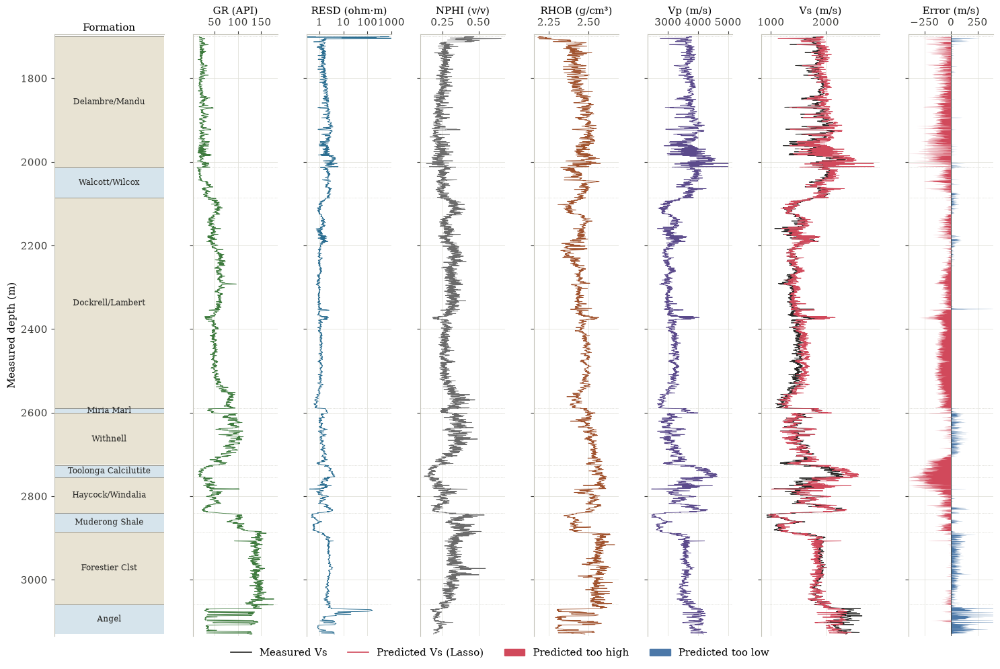

In [58]:
# --- Thesis depth plot: Lasso LOWO prediction in one well ---
PLOT_WELL = 'Lambert_8B_with_formation'

train_df = data_df[(data_df['Well Name'] != PLOT_WELL) & (data_df['Well Name'].isin(measured_wells))]
w = data_df[data_df['Well Name'] == PLOT_WELL].copy()
scaler = StandardScaler()
model = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)
model.fit(scaler.fit_transform(train_df[features_reg]), train_df[target_reg])
w['VS_PRED'] = model.predict(scaler.transform(w[features_reg]))
w['VS_MEAS'] = w[target_reg]

w = w.sort_values('MD').reset_index(drop=True)
w['ERR'] = w['VS_MEAS'] - w['VS_PRED']                 # + = predicted too low
# break lines where samples were removed (depth jump > 1 m)
w.loc[w['MD'].diff() > 1, ['GR_EDITED', 'RESD_EDITED', 'NPHI_EDITED', 'RHOB_EDITED', 'VP_EDITED', 'VS_MEAS', 'VS_PRED', 'ERR']] = np.nan

with plt.rc_context({'font.family': 'serif', 'font.size': 11,
                     'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
                     'xtick.color': '#3d3d3a', 'ytick.color': '#3d3d3a'}):
    fig, ax = plt.subplots(1, 8, figsize=(15, 10), sharey=True,
                           gridspec_kw={'width_ratios': [1.3, 1, 1, 1, 1, 1, 1.4, 1]})

    # 1. Formations
    fm = (w.dropna(subset=['Formation']).groupby('Formation', sort=False)['MD']
            .agg(['min', 'max']).sort_values('min'))
    fm_cols = ['#e8e3d3', '#d6e4ec']
    for k, (name, row) in enumerate(fm.iterrows()):
        ax[0].axhspan(row['min'], row['max'], color=fm_cols[k % 2], lw=0)
        ax[0].axhline(row['min'], color='#8c8a80', lw=0.6)
        ax[0].text(0.5, (row['min'] + row['max']) / 2, name.replace(' Fms', '').replace(' Fm', ''),
                   ha='center', va='center', fontsize=8.5, color='#262624')
    ax[0].set_xticks([]); ax[0].set_xlabel('Formation')

    # 2. GR
    ax[1].plot(w['GR_EDITED'], w['MD'], color='#3d7a3d', lw=0.6)
    ax[1].set_xlabel('GR (API)')

    # 3. Resistivity (log scale)
    ax[2].plot(w['RESD_EDITED'], w['MD'], color='#2c6e91', lw=0.6)
    ax[2].set_xscale('log'); ax[2].set_xlabel('RESD (ohm·m)')
    ax[2].set_xlim(0.3, 1000)
    ax[2].set_xticks([1, 10, 100, 1000]); ax[2].set_xticklabels(['1', '10', '100', '1000'])
    ax[2].minorticks_off()

    # 4. NPHI
    ax[3].plot(w['NPHI_EDITED'], w['MD'], color='#6b6b6b', lw=0.6)
    ax[3].set_xlabel('NPHI (v/v)')

    # 5. RHOB
    ax[4].plot(w['RHOB_EDITED'], w['MD'], color='#a0522d', lw=0.6)
    ax[4].set_xlabel('RHOB (g/cm³)')

    # 6. Vp
    ax[5].plot(w['VP_EDITED'], w['MD'], color='#5b4a8b', lw=0.6)
    ax[5].set_xlabel('Vp (m/s)')
    ax[5].set_xticks([3000, 4000, 5000])

    # 7. Measured vs predicted Vs
    ax[6].plot(w['VS_MEAS'], w['MD'], color='#262624', lw=0.6)
    ax[6].plot(w['VS_PRED'], w['MD'], color='#d1495b', lw=0.6)
    ax[6].set_xlabel('Vs (m/s)')

    # 8. Error
    ax[7].fill_betweenx(w['MD'], 0, w['ERR'], where=w['ERR'] > 0, color='#4c78a8', lw=0, interpolate=True)
    ax[7].fill_betweenx(w['MD'], 0, w['ERR'], where=w['ERR'] < 0, color='#d1495b', lw=0, interpolate=True)
    ax[7].axvline(0, color='#3d3d3a', lw=0.7)
    lim = np.nanpercentile(np.abs(w['ERR']), 99.5) * 1.1
    ax[7].set_xlim(-lim, lim)
    ax[7].set_xlabel('Error (m/s)')

    for a in ax:
        a.xaxis.set_label_position('top'); a.xaxis.tick_top()
        for side in ['right', 'bottom']:
            a.spines[side].set_visible(False)
    for a in ax[1:]:
        a.grid(color='#e1e0d9', lw=0.6); a.set_axisbelow(True)
        for b in fm['min']:
            a.axhline(b, color='#c3c2b7', lw=0.5, ls=':', zorder=0)
    ax[0].set_ylim(w['MD'].max() + 5, w['MD'].min() - 5)
    ax[0].set_ylabel('Measured depth (m)')

    # one legend under all tracks
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    handles = [Line2D([], [], color='#262624', lw=1.2, label='Measured Vs'),
               Line2D([], [], color='#d1495b', lw=1.2, label='Predicted Vs (Lasso)'),
               Patch(color='#d1495b', label='Predicted too high'),
               Patch(color='#4c78a8', label='Predicted too low')]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=11,
               bbox_to_anchor=(0.5, 0))
    plt.tight_layout(w_pad=1.2, rect=(0, 0.03, 1, 1))
    name = PLOT_WELL.replace('_with_formation', '')
    plt.savefig(FIGURES_DIR / f"lasso_depth_{name}_thesis_all_logs.png", dpi=300, bbox_inches='tight')
    plt.show()

# Part 4 — Validation scheme figure (Methodology)

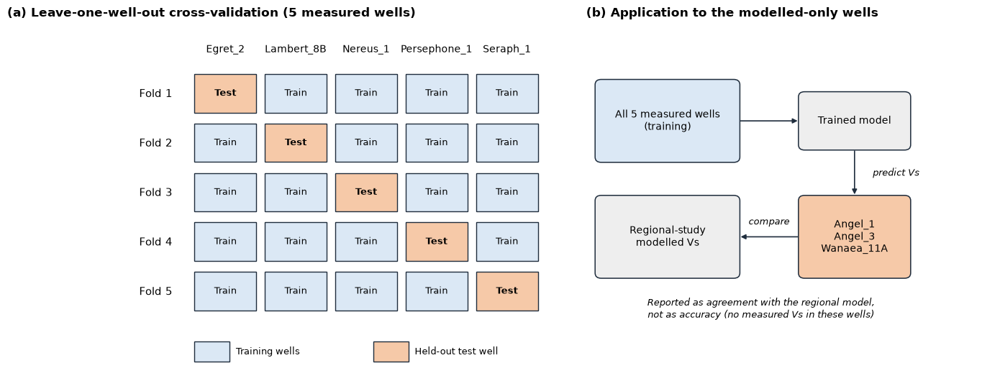

In [59]:
# ===========================================================================
# Figure 3.7 - Validation scheme: (a) LOWO folds, (b) modelled-only wells
# ===========================================================================
from matplotlib.patches import FancyBboxPatch, Rectangle

INK, TR, TE, MOD = '#1f2d3d', '#dbe8f5', '#f6c9a8', '#eeeeee'
wells_plot = ['Egret_2', 'Lambert_8B', 'Nereus_1', 'Persephone_1', 'Seraph_1']

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.4),
                           gridspec_kw={'width_ratios': [1.35, 1]})

# ---------- (a) Leave-one-well-out folds ----------
a.set_xlim(-2.6, 5.2); a.set_ylim(-1.2, 5.9); a.axis('off')

for j, w in enumerate(wells_plot):
    a.text(j + 0.5, 5.25, w, ha='center', va='bottom', fontsize=10)

for i in range(5):
    y = 4 - i
    a.text(-0.25, y + 0.45, f'Fold {i+1}', ha='right', va='center', fontsize=10.5)
    for j in range(5):
        test = (i == j)
        a.add_patch(Rectangle((j + 0.06, y + 0.08), 0.88, 0.78,
                              fc=TE if test else TR, ec=INK, lw=1))
        a.text(j + 0.5, y + 0.47, 'Test' if test else 'Train',
               ha='center', va='center', fontsize=9.5,
               fontweight='bold' if test else 'normal')

# legend
a.add_patch(Rectangle((0.06, -0.95), 0.5, 0.4, fc=TR, ec=INK, lw=1))
a.text(0.65, -0.75, 'Training wells', va='center', fontsize=9.5)
a.add_patch(Rectangle((2.6, -0.95), 0.5, 0.4, fc=TE, ec=INK, lw=1))
a.text(3.19, -0.75, 'Held-out test well', va='center', fontsize=9.5)

a.set_title('(a) Leave-one-well-out cross-validation (5 measured wells)',
            loc='left', fontsize=12, fontweight='bold')

# ---------- (b) Application to modelled-only wells ----------
b.set_xlim(0, 10); b.set_ylim(0, 10); b.axis('off')

def box(x, y, w, h, t, fc):
    b.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h,
                               boxstyle='round,pad=0.08,rounding_size=0.15',
                               fc=fc, ec=INK, lw=1.1))
    b.text(x, y, t, ha='center', va='center', fontsize=10)

def arr(x1, y1, x2, y2):
    b.annotate('', xy=(x2, y2), xytext=(x1, y1),
               arrowprops=dict(arrowstyle='-|>', color=INK, lw=1.2))

box(2.0, 7.2, 3.4, 2.2, 'All 5 measured wells\n(training)', TR)
box(6.6, 7.2, 2.6, 1.5, 'Trained model', MOD)
arr(3.75, 7.2, 5.25, 7.2)

box(6.6, 3.9, 2.6, 2.2, 'Angel_1\nAngel_3\nWanaea_11A', TE)
arr(6.6, 6.4, 6.6, 5.05)
b.text(7.05, 5.72, 'predict Vs', fontsize=9.5, style='italic', va='center')

box(2.0, 3.9, 3.4, 2.2, 'Regional-study\nmodelled Vs', MOD)
arr(5.25, 3.9, 3.75, 3.9)
b.text(4.5, 4.25, 'compare', fontsize=9.5, style='italic', ha='center')

b.text(4.3, 1.6, 'Reported as agreement with the regional model,\n'
                 'not as accuracy (no measured Vs in these wells)',
       ha='center', fontsize=9.5, style='italic')

b.set_title('(b) Application to the modelled-only wells',
            loc='left', fontsize=12, fontweight='bold')

plt.tight_layout(w_pad=3)
plt.savefig(FIGURES_DIR / "Figure_3.7_validation_scheme.png",
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### Porosity check: Toolonga Calcilutite

Table 1 - Toolonga medians per well


,rows,PHIT,PHID,NPHI,RHOB,GR,Vp,Vs,VpVs
Well,,,,,,,,,
Egret_2,230,0.065,0.082,0.098,2.571,16.055,4205.457,2231.207,1.895
Lambert_8B,192,0.097,0.083,0.175,2.569,21.753,4253.469,2095.483,2.034
Nereus_1,513,0.086,0.088,0.139,2.559,28.549,4069.797,2033.208,1.992
Persephone_1,1037,0.070,0.095,0.150,2.548,52.144,3805.267,2402.022,1.603



Table 2 - Toolonga velocities at matched porosity


rows       Vp       Vs  VpVs
PHIT range   Well                                      
(0.04, 0.07] Egret_2        103  4205.48  2222.57  1.93
             Nereus_1       109  3955.37  1896.50  2.11
             Persephone_1   413  3887.12  2423.24  1.60
(0.07, 0.1]  Egret_2         68  4221.02  2274.68  1.87
             Lambert_8B     115  4295.63  2106.68  2.04
             Nereus_1       264  3883.11  1901.40  2.01
             Persephone_1   349  3649.22  2396.27  1.58
(0.1, 0.13]  Egret_2         21  4245.97  2310.24  1.83
             Lambert_8B      77  4105.04  2079.32  2.03
             Nereus_1       115  4197.52  2187.14  1.94
             Persephone_1   142  3274.71  2108.84  1.62

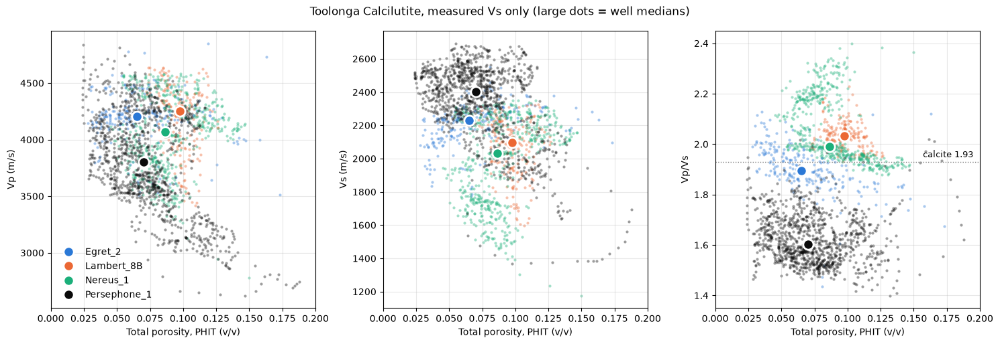

In [60]:
# --- Porosity check: Toolonga Calcilutite, Persephone_1 vs the other wells ---
# Is Persephone_1's low Vp/Vs explained by porosity? Compare Vp, Vs and Vp/Vs at the same porosity.
RHO_CALCITE, RHO_FLUID = 2.71, 1.0                     # g/cc, for density porosity

tp = data_df[data_df['Formation'] == 'Toolonga Calcilutite'].copy()
tp['Well'] = tp['Well Name'].str.replace('_with_formation', '')
tp['VpVs'] = tp['VP_EDITED'] / tp['VS_EDITED_V2']
tp['PHID'] = (RHO_CALCITE - tp['RHOB_EDITED']) / (RHO_CALCITE - RHO_FLUID)   # density porosity, calcite matrix

# Table 1: porosity and velocities per well (medians)
print("Table 1 - Toolonga medians per well")
display(tp.groupby('Well').agg(
    rows=('MD', 'size'),
    PHIT=('PHIT_QEPP', 'median'),
    PHID=('PHID', 'median'),
    NPHI=('NPHI_EDITED', 'median'),
    RHOB=('RHOB_EDITED', 'median'),
    GR=('GR_EDITED', 'median'),
    Vp=('VP_EDITED', 'median'),
    Vs=('VS_EDITED_V2', 'median'),
    VpVs=('VpVs', 'median'),
).round(3))

# Table 2: velocities at the same porosity
tp['PHIT range'] = pd.cut(tp['PHIT_QEPP'], [0.04, 0.07, 0.10, 0.13])
print("\nTable 2 - Toolonga velocities at matched porosity")
display(tp.groupby(['PHIT range', 'Well'], observed=True).agg(
    rows=('MD', 'size'),
    Vp=('VP_EDITED', 'median'),
    Vs=('VS_EDITED_V2', 'median'),
    VpVs=('VpVs', 'median'),
).round(2))

# Figure: Vp, Vs and Vp/Vs against porosity
colours = {'Egret_2': '#2a78d6', 'Lambert_8B': '#eb6834',
           'Nereus_1': '#1baf7a', 'Persephone_1': '#0b0b0b'}
fig, axs = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, col, label in zip(axs, ['VP_EDITED', 'VS_EDITED_V2', 'VpVs'], ['Vp (m/s)', 'Vs (m/s)', 'Vp/Vs']):
    for w, c in colours.items():
        s = tp[tp['Well'] == w]
        if s.empty:
            continue
        ax.scatter(s['PHIT_QEPP'], s[col], s=9, color=c, alpha=0.4, lw=0)
        ax.plot(s['PHIT_QEPP'].median(), s[col].median(), 'o', ms=11,
                color=c, mec='white', mew=2, zorder=5, label=w)
    ax.set_xlabel('Total porosity, PHIT (v/v)')
    ax.set_ylabel(label)
    ax.set_xlim(0, 0.2)
    ax.grid(alpha=0.3)
axs[2].axhline(1.93, color='grey', ls=':', lw=1)
axs[2].text(0.195, 1.94, 'calcite 1.93', ha='right', va='bottom', fontsize=9)
axs[0].legend(loc='lower left', frameon=False)
fig.suptitle('Toolonga Calcilutite, measured Vs only (large dots = well medians)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'Toolonga_porosity_check.png', dpi=300, bbox_inches='tight')
plt.show()

### Export the cleaned training table (used by notebook 06)

In [61]:
# ---- Export for fluid substitution: cleaned measured-Vs table (5 wells) ----
cols = ["Well Name", "MD"] + features_reg + [target_reg]
data_df[data_df["Well Name"].isin(measured_wells)][cols].to_csv(
    RESULTS_DIR / "lasso_training_5wells.csv", index=False)
print("saved;  best_alpha =", best_alpha)

saved;  best_alpha = 7.278953843983154
